# Seminar 3. Gradient Descent and Automatic Differentiation

Checks for every number in the data sections of `content/public.json` and `content/students.json`; the notebook also draws the figures and writes the data file of the page and the LaTeX sources of the handout and the cheat sheet.

## 1. Setup

Every leaf of the two data sections is compared with a value computed here, and the coverage is checked at the end. Exact values are kept as `Fraction`s where the arithmetic allows.

In [1]:
import copy
import difflib
import io
import json
import logging
import math
import re
import zlib
from datetime import date, datetime, time, timedelta, timezone
from decimal import ROUND_HALF_UP, Decimal
from fractions import Fraction as Fr
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

SEED = 42
TOPIC = "Gradient Descent and Automatic Differentiation"
SEMINAR = "03"
NOTEBOOK = f"{SEMINAR}. {TOPIC}.ipynb"


def find_author_root(start):
    """The folder Seminars/Evgeny Baulin, searched from start upwards."""
    for base in (start, *start.parents):
        for cand in (base, base / "Seminars" / "Evgeny Baulin"):
            if (cand / "checks" / NOTEBOOK).is_file():
                return cand
    raise FileNotFoundError(f"Seminars/Evgeny Baulin/checks/{NOTEBOOK} not found above {start}")


AUTHOR = find_author_root(Path.cwd())
ROOT = AUTHOR.parents[1]
NB_PATH = AUTHOR / "checks" / NOTEBOOK
THEORY = AUTHOR / "theory" / f"{SEMINAR}. {TOPIC}"
CONTENT = THEORY / "content"
FIG_DIR = THEORY / "figures"
WEB = AUTHOR / "web" / SEMINAR
CONTENT_FILES = [WEB / "js" / f"content-{name}.js"
                 for name in ("ui", "main", "problems", "handout", "cheatsheet")]
np.set_printoptions(precision=6, suppress=True)


def strict_loads(text, name):
    """JSON without NaN, Infinity or repeated keys."""
    def pairs(items):
        keys = [k for k, _ in items]
        if len(keys) != len(set(keys)):
            raise ValueError(f"{name}: a repeated key among {keys}")
        return dict(items)

    def constant(value):
        raise ValueError(f"{name}: {value} is not JSON")

    return json.loads(text, object_pairs_hook=pairs, parse_constant=constant)


def strict_json(path):
    return strict_loads(path.read_text(encoding="utf-8"), path.name)


def marked_json(path):
    """The JSON between /*JSON-BEGIN*/ and /*JSON-END*/ of a content file, and the text around it."""
    text = path.read_text(encoding="utf-8")
    m = re.search(r"/\*JSON-BEGIN\*/(.*)/\*JSON-END\*/", text, re.S)
    if m is None:
        raise ValueError(f"{path.name}: no JSON markers")
    return strict_loads(m.group(1), path.name), text[:m.start()] + text[m.end():]


def write_if_changed(path, content):
    """Write text or bytes only when they differ from the file; True when written."""
    content = content.encode("utf-8") if isinstance(content, str) else content
    if path.is_file() and path.read_bytes() == content:
        return False
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(content)
    return True


PUBLIC = strict_json(CONTENT / "public.json")
PUBLIC["content"] = {k: v for path in CONTENT_FILES for k, v in marked_json(path)[0].items()}
STUDENTS = strict_json(CONTENT / "students.json")
PUB, STU = PUBLIC["data"], STUDENTS["data"]
CHECKS = []
COVERED = set()
MISSING = object()


def short(value, width=40):
    if isinstance(value, np.ndarray):
        value = value.tolist()
    if isinstance(value, (list, tuple)):
        text = "[" + ", ".join(short(v, 10**6) for v in value) + "]"
    elif isinstance(value, dict):
        text = "{" + ", ".join(f"{k}: {short(v, 10**6)}" for k, v in value.items()) + "}"
    elif isinstance(value, (float, np.floating)):
        text = f"{float(value):.10g}"
    else:
        text = str(value)
    return text if len(text) <= width else text[:width - 3] + "..."


def same(computed, expected, tol):
    if isinstance(expected, bool):
        return isinstance(computed, (bool, np.bool_)) and bool(computed) == expected
    if isinstance(expected, str):
        return isinstance(computed, str) and computed == expected
    if isinstance(expected, dict):
        return (isinstance(computed, dict) and list(computed) == list(expected)
                and all(same(computed[k], expected[k], tol) for k in expected))
    if isinstance(expected, (list, tuple)):
        return (isinstance(computed, (list, tuple, np.ndarray)) and len(computed) == len(expected)
                and all(same(c, e, tol) for c, e in zip(computed, expected)))
    if expected is None or computed is None or isinstance(computed, (bool, np.bool_, str, dict, list)):
        return False
    c, e = float(computed), float(expected)
    return math.isfinite(c) and abs(c - e) <= tol


def check(name, computed, expected, tol=1e-12):
    """Numbers within tol (absolute); strings, booleans, lists and dicts entry by entry."""
    passed = same(computed, expected, tol)
    CHECKS.append({"check": name, "computed": short(computed), "expected": short(expected),
                   "detail": short(computed, 600), "passed": passed})
    return passed


def section(prefix):
    """The checks whose names start with prefix, one line each."""
    rows = [c for c in CHECKS if c["check"].startswith(prefix + ":")]
    width = max(len(c["check"]) for c in rows)
    for c in rows:
        tail = "ok" if c["passed"] else f"FAILED, expected {c['expected']}"
        print(f"{c['check']:<{width}}  {c['computed']:<40}  {tail}")


def at(root, path):
    """The node at a dotted path, list entries counted from 1."""
    node = root
    for part in path.split("."):
        if isinstance(node, dict) and part in node:
            node = node[part]
        elif isinstance(node, list) and part.isdigit() and 1 <= int(part) <= len(node):
            node = node[int(part) - 1]
        else:
            return MISSING
    return node


def leaves(node, path):
    if isinstance(node, dict):
        for k, v in node.items():
            yield from leaves(v, f"{path}.{k}")
    elif isinstance(node, list):
        for i, v in enumerate(node, start=1):
            yield from leaves(v, f"{path}.{i}")
    else:
        yield path


def nodes(node):
    if isinstance(node, dict):
        yield node
        for v in node.values():
            yield from nodes(v)
    elif isinstance(node, list):
        for v in node:
            yield from nodes(v)


def lookup(path):
    """(file, node) for a data path that sits in exactly one of the two data sections."""
    found = [(name, at(root, path)) for name, root in (("public", PUB), ("students", STU))]
    found = [(name, node) for name, node in found if node is not MISSING]
    return found[0] if len(found) == 1 else (None, MISSING)


def group(path):
    head, *rest = path.split(".")
    return {"answers": rest[0] if rest else head, "zero": "0", "release": "timeline"}.get(head, head)


def expect(path, computed, tol=1e-12):
    """Compare a computed value with the data leaf at path and mark the leaf as checked."""
    name, expected = lookup(path)
    if expected is MISSING:
        return check(f"{group(path)}: {path} (missing in the data)", computed, None)
    COVERED.update((name, p) for p in leaves(expected, path))
    return check(f"{group(path)}: {path}", computed, expected, tol)


def expect_answer(path, computed):
    """Answer spec: the computed value, and a tolerance that takes 4 significant digits but not 1% off."""
    pid, key = path.split(".")
    name, spec = lookup(f"answers.{path}")
    if spec is MISSING:
        return check(f"{pid}: answer {key} (missing in the data)", computed, None)
    COVERED.update((name, p) for p in leaves(spec, f"answers.{path}"))
    value, tol = spec.get("value"), spec.get("tol")
    integer = isinstance(computed, (int, Fr)) and Fr(computed).denominator == 1
    typed = float(computed) if integer else float(f"{float(computed):.4g}")

    def accepted(a):
        return abs(a - value) <= tol * max(1, abs(value))

    check(f"{pid}: answer {key} is a number spec", [sorted(spec), spec.get("type")],
          [["tol", "type", "value"], "number"])
    check(f"{pid}: answer {key} equals the computed value", abs(value - float(computed)), 0.0,
          1e-8 * max(1, abs(float(computed))))
    check(f"{pid}: answer {key}: the tolerance accepts {typed:g}", accepted(typed), True)
    check(f"{pid}: answer {key}: the tolerance rejects a 1% error",
          not accepted(float(computed) * 1.01) and not accepted(float(computed) * 0.99), True)


def s6(v):
    """Six decimals, as the page prints them."""
    text = f"{float(v):.6f}"
    return "0.000000" if text == "-0.000000" else text


def fixed(v, n):
    return f"{float(v):.{n}f}"


def g5(v):
    return f"{float(v):.5g}"


def sci(v, digits):
    """v as 'm \\cdot 10^{e}' in TeX with the given number of significant digits."""
    mantissa, exponent = f"{float(v):.{digits - 1}e}".split("e")
    return f"{mantissa} \\cdot 10^{{{int(exponent)}}}"


def dec(q):
    """The exact decimal of a Fraction whose denominator has no prime factors other than 2 and 5."""
    q = Fr(q)
    sign, q = ("-" if q < 0 else ""), abs(q)
    n = 0
    while (q * 10**n).denominator != 1:
        n += 1
        assert n < 60, q
    digits = str(int(q * 10**n)).rjust(n + 1, "0")
    return sign + (digits if n == 0 else digits[:-n] + "." + digits[-n:])


def tfrac(q):
    return f"\\tfrac{{{q.numerator}}}{{{q.denominator}}}"


def pow10(q):
    e = round(math.log10(q))
    assert Fr(10) ** e == q, q
    return f"10^{{{e}}}"


def first_power_below(ratio, gap):
    """The least k with ratio**k <= gap, for Fractions 0 < ratio < 1, checked in integers."""
    k = max(1, math.ceil(math.log(gap) / math.log(ratio)) - 2)
    while ratio ** (k - 1) <= gap:
        k -= 1
    while ratio**k > gap:
        k += 1
    return k


print(f"numpy {np.__version__} | matplotlib {matplotlib.__version__} | seed {SEED}")
print(f"notebook: {NB_PATH.relative_to(ROOT)}")
print(f"data leaves: {len(list(leaves(PUB, 'p')))} public, {len(list(leaves(STU, 's')))} students")

numpy 2.5.2 | matplotlib 3.11.1 | seed 42
notebook: Seminars/Evgeny Baulin/checks/03. Gradient Descent and Automatic Differentiation.ipynb
data leaves: 262 public, 227 students


## 2. Gradient descent and the line search

$x_{k+1}=x_k-\alpha\nabla f(x_k)$. Backtracking accepts $\alpha$ when $f(x+\alpha d)\le f(x)+c\,\alpha\,\nabla f(x)^\top d$ and otherwise multiplies it by $\beta$; each stopping test compares a quantity with $\mathrm{atol}+\mathrm{rtol}\cdot\max(1,\text{scale})$.

In [2]:
def gradient_descent(f, grad, x0, step, tol=1e-8, max_iter=10_000):
    """Fixed step; history holds the lists 'x', 'f', 'grad_norm' and 'step', as in the course notebook."""
    x = np.asarray(x0, dtype=float).copy()
    history = {"x": [x.copy()], "f": [float(f(x))], "grad_norm": [], "step": []}
    for _ in range(max_iter):
        g = np.asarray(grad(x), dtype=float)
        gn = float(np.linalg.norm(g))
        history["grad_norm"].append(gn)
        if not np.isfinite(gn):
            raise FloatingPointError("non-finite gradient")
        if gn <= tol:
            break
        x = x - step * g
        fx = float(f(x))
        if not np.isfinite(fx):
            raise FloatingPointError("non-finite objective")
        history["x"].append(x.copy())
        history["f"].append(fx)
        history["step"].append(step)
    return x, history


def backtracking(f, x, g, d, alpha0=1.0, beta=0.5, c=1e-4, max_halvings=60):
    """Armijo backtracking along a descent direction d; returns (alpha, halvings)."""
    slope = float(g @ d)
    if slope >= 0:
        raise ValueError("d is not a descent direction")
    fx = float(f(x))
    alpha = float(alpha0)
    for halvings in range(max_halvings + 1):
        if f(x + alpha * d) <= fx + c * alpha * slope:
            return alpha, halvings
        alpha *= beta
    raise RuntimeError("no step passed the Armijo test")


def stopping_tests(f_old, f_new, x_old, x_new, g_new, atol=1e-8, rtol=1e-6):
    """Each test as (value, threshold); a test fires when value <= threshold."""
    return {
        "gradient": (float(np.linalg.norm(g_new)), atol + rtol * max(1.0, abs(f_new))),
        "step": (float(np.linalg.norm(x_new - x_old)), atol + rtol * max(1.0, float(np.linalg.norm(x_old)))),
        "function": (abs(f_new - f_old), atol + rtol * max(1.0, abs(f_old))),
    }


def quadratic(lam):
    """f(x) = x^T diag(lam) x / 2 and its gradient."""
    lam = np.asarray(lam, dtype=float)

    def f(x):
        return 0.5 * float(np.sum(lam * x * x))

    def grad(x):
        return lam * x

    return f, grad


f, grad = quadratic([1, 10])
x, hist = gradient_descent(f, grad, [2, 2], **{"step": 0.1})
n = len(hist["step"])
check("GD: the interface method(f, grad, x0, **params) converges at step 1/L",
      hist["grad_norm"][-1] <= 1e-8, True)
check("GD: history lengths of x, f, grad_norm and step",
      [len(hist[k]) for k in ("x", "f", "grad_norm", "step")], [n + 1, n + 1, n + 1, n])
check("GD: f decreases at every step when step = 1/L", bool(np.all(np.diff(hist["f"]) < 0)), True)
try:
    with np.errstate(over="ignore", invalid="ignore"):
        gradient_descent(f, grad, [2, 2], step=0.21)
    stopped = False
except FloatingPointError:
    stopped = True
check("GD: a step above 2/L ends in FloatingPointError", stopped, True)
x0 = np.array([2.0, 2.0])
try:
    backtracking(f, x0, grad(x0), grad(x0))
    refused = False
except ValueError:
    refused = True
check("GD: backtracking refuses an ascent direction", refused, True)
check("GD: the three stopping tests", sorted(stopping_tests(1.0, 0.5, x0, x0 / 2, grad(x0 / 2))),
      ["function", "gradient", "step"])
section("GD")

GD: the interface method(f, grad, x0, **params) converges at step 1/L  True                                      ok
GD: history lengths of x, f, grad_norm and step                        [183, 183, 183, 182]                      ok
GD: f decreases at every step when step = 1/L                          True                                      ok
GD: a step above 2/L ends in FloatingPointError                        True                                      ok
GD: backtracking refuses an ascent direction                           True                                      ok
GD: the three stopping tests                                           [function, gradient, step]                ok


## 3. Jensen's inequality

$f\big((1-t)x+ty\big)\le(1-t)f(x)+tf(y)$ for $t\in[0,1]$. For $x^2$ the gap is exactly $(1-t)x^2+ty^2-\big((1-t)x+ty\big)^2=t(1-t)(x-y)^2$, and for $-\log$ at $t=\tfrac12$ the inequality is AM–GM.

In [3]:
def chord_gap(fun, x, y, t):
    """(1 - t) f(x) + t f(y) - f((1 - t) x + t y); negative means Jensen fails."""
    return (1 - t) * fun(x) + t * fun(y) - fun((1 - t) * x + t * y)


# x^3 on the whole line
x, y, t = Fr(-2), Fr(1), Fr(1, 2)
mid = (1 - t) * x + t * y
for key, value in {"x": x, "y": y, "t": t, "mid": mid, "lhs": mid**3,
                   "rhs": (1 - t) * x**3 + t * y**3}.items():
    expect(f"zero.x3.{key}", value)
check("0: x^3 breaks Jensen at the counterexample", chord_gap(lambda s: s**3, x, y, t) < 0, True)

# x^2 with t outside [0, 1]
x, y, t = Fr(0), Fr(1), Fr(2)
point = (1 - t) * x + t * y
for key, value in {"x": x, "y": y, "t": t, "point": point, "lhs": point**2,
                   "rhs": (1 - t) * x**2 + t * y**2}.items():
    expect(f"zero.x2out.{key}", value)
check("0: x^2 breaks the inequality at t = 2, as t(1-t)(x-y)^2 < 0", chord_gap(lambda s: s * s, x, y, t),
      t * (1 - t) * (x - y) ** 2)

rng = np.random.default_rng(SEED)
triples = [(Fr(int(a), 7), Fr(int(b), 5), Fr(int(c), 11)) for a, b, c in rng.integers(-60, 60, size=(300, 3))]
check("0: the x^2 identity holds exactly on 300 random rational triples",
      all(chord_gap(lambda s: s * s, x, y, t) == t * (1 - t) * (x - y) ** 2 for x, y, t in triples), True)

a, b = 1, 9
gm, am = math.isqrt(a * b), Fr(a + b, 2)
assert gm * gm == a * b
for key, value in {"a": a, "b": b, "gm": gm, "am": am}.items():
    expect(f"zero.amgm.{key}", value)
check("0: Jensen for -log at t = 1/2 is AM-GM", chord_gap(lambda s: -math.log(s), a, b, 0.5) >= 0,
      gm <= am)
section("0")

0: zero.x3.x                                                      -2                                        ok
0: zero.x3.y                                                      1                                         ok
0: zero.x3.t                                                      1/2                                       ok
0: zero.x3.mid                                                    -1/2                                      ok
0: zero.x3.lhs                                                    -1/8                                      ok
0: zero.x3.rhs                                                    -7/2                                      ok
0: x^3 breaks Jensen at the counterexample                        True                                      ok
0: zero.x2out.x                                                   0                                         ok
0: zero.x2out.y                                                   1                                         ok
0

## 4. Step size and conditioning

For $f(x)=\tfrac12x^\top Qx$ with $Q=\mathrm{diag}(\lambda_1,\lambda_2)$ every step multiplies coordinate $i$ by $1-\alpha\lambda_i$, so $f(x_k)=\tfrac12\sum_i\lambda_i(1-\alpha\lambda_i)^{2k}x_{0,i}^2$. At $\alpha=1/L$ the guarantee is $f(x_k)-f^*\le(1-\mu/L)^k\big(f(x_0)-f^*\big)$, which gives $k\ge\ln(10^{-6})/\ln(1-\mu/L)$ for a gap cut by $10^6$.

### A1. Four steps on $\mathrm{diag}(1,10)$

At $\alpha=2/L$ the stiff coordinate flips between $+2$ and $-2$ and alone contributes $\tfrac12\cdot10\cdot2^2=20$, so $f(x_k)=20+2\cdot0.64^k$.

In [4]:
def f_closed(lam, x0, alpha, k):
    """f(x_k) in exact arithmetic from the per-coordinate factors 1 - alpha * lam_i."""
    return sum(Fr(l) * (1 - alpha * l) ** (2 * k) * Fr(x) ** 2 for l, x in zip(lam, x0)) / 2


A1_lam, A1_x0 = [1, 10], [2, 2]
A1_alphas = [Fr("0.05"), Fr("0.19"), Fr("0.2"), Fr("0.21")]
expect("A1.params.lam", A1_lam)
expect("A1.params.x0", A1_x0)
expect("A1.params.alphas", A1_alphas)

eig = np.linalg.eigvalsh(np.diag(np.array(A1_lam, dtype=float)))
L, mu = Fr(int(round(eig[-1]))), Fr(int(round(eig[0])))
check("A1: eigenvalues of Q", eig, [mu, L])
expect("A1.L", eig[-1])
expect("A1.mu", eig[0])
expect("A1.kappa", eig[-1] / eig[0])
expect("A1.invL", 1 / L)
expect("A1.twoL", 2 / L)
expect("A1.f0", f_closed(A1_lam, A1_x0, 0, 0))
factors = [[1 - a * l for l in A1_lam] for a in A1_alphas]
expect("A1.factors", factors)
expect("A1.optStep", tfrac(2 / (L + mu)))

f, grad = quadratic(A1_lam)
closed, runs = {}, {}
for a in A1_alphas:
    closed[a] = [f_closed(A1_lam, A1_x0, a, k) for k in range(101)]
    _, hist = gradient_descent(f, grad, A1_x0, step=float(a), tol=0.0, max_iter=100)
    runs[a] = hist
worst = max(abs(runs[a]["f"][k] - float(closed[a][k])) / float(closed[a][k])
            for a in A1_alphas for k in range(101))
check("A1: simulation against the closed form over 100 steps, largest relative difference", worst, 0.0, 1e-12)
expect("A1.f10", [fixed(closed[a][10], 4) for a in A1_alphas])
expect("A1.f50", [sci(closed[a][50], 3) for a in A1_alphas])

# at 2/L: the stiff coordinate keeps its size, the flat one shrinks by 1 - 2 mu / L per step
a = 2 / L
stall = L * Fr(A1_x0[1]) ** 2 / 2
flat = mu * Fr(A1_x0[0]) ** 2 / 2
ratio = (1 - a * mu) ** 2
expect("A1.stall", stall)
expect("A1.stallCoord", abs(runs[a]["x"][-1][1]))
expect("A1.stallRatio", ratio)
check("A1: the stiff coordinate is +-2 at every step at 2/L",
      sorted({float(abs(p[1])) for p in runs[a]["x"]}), [2.0])
check("A1: f(x_k) = 20 + 2 * 0.64^k exactly for k = 0..100 at 2/L",
      all(closed[a][k] == stall + flat * ratio**k for k in range(101)), True)
check("A1: f(x_k) stays above 20 at 2/L", min(closed[a]) > stall, True)
check("A1: 0.05 and 0.19 converge, 0.2 and 0.21 do not",
      [max(abs(v) for v in row) < 1 for row in factors], [True, True, False, False])
check("A1: the sign flips in the stiff coordinate start above 1/L", [row[1] < 0 for row in factors],
      [False, True, True, True])
check("A1: f grows at 0.21", closed[A1_alphas[3]][100] > closed[A1_alphas[3]][0], True)

# stability boundary: bisection on the spectral radius of I - alpha Q
lo, hi = 0.0, 1.0
for _ in range(80):
    m = (lo + hi) / 2
    lo, hi = (m, hi) if max(abs(1 - m * eig)) < 1 else (lo, m)
check("A1: bisection on the spectral radius of I - alpha Q gives 2/L", lo, 2 / L, 1e-12)
expect_answer("A1.boundary", 2 / L)
section("A1")

A1: A1.params.lam                                                                   [1, 10]                                   ok
A1: A1.params.x0                                                                    [2, 2]                                    ok
A1: A1.params.alphas                                                                [1/20, 19/100, 1/5, 21/100]               ok
A1: eigenvalues of Q                                                                [1, 10]                                   ok
A1: A1.L                                                                            10                                        ok
A1: A1.mu                                                                           1                                         ok
A1: A1.kappa                                                                        10                                        ok
A1: A1.invL                                                                         1/10         

### A2. $\mathrm{diag}(1,2)$ at $\alpha=1/L$

"Observed" is the first $k$ with $f(x_k)\le10^{-6}f(x_0)$, found from the exact closed form and from the run of `gradient_descent`. At $\alpha=1/L$ the stiff coordinate vanishes after one step, so $f(x_k)=\tfrac12\mu x_{0,1}^2(1-\mu/L)^{2k}$ for $k\ge1$ and the crossing can be solved for a real $k$.

In [5]:
GAP = Fr(1, 10**6)


def rate_summary(lam, x0):
    """kappa, the bound at 1/L and the observed count, each by two routes."""
    eig = np.linalg.eigvalsh(np.diag(np.array(lam, dtype=float)))
    L, mu = Fr(max(lam)), Fr(min(lam))
    alpha = 1 / L
    factor = 1 - mu / L
    raw = math.log(GAP) / math.log(factor)
    f0 = f_closed(lam, x0, 0, 0)
    observed = next(k for k in range(1, 10**5) if f_closed(lam, x0, alpha, k) <= GAP * f0)
    f, grad = quadratic(lam)
    _, hist = gradient_descent(f, grad, x0, step=float(alpha), tol=0.0, max_iter=math.ceil(raw))
    simulated = next(k for k, v in enumerate(hist["f"]) if v <= float(GAP) * hist["f"][0])
    # after the first step only the flat coordinate is left
    flat = lam.index(min(lam))
    tail = mu * Fr(x0[flat]) ** 2 / 2
    tail_exact = all(f_closed(lam, x0, alpha, k) == tail * factor ** (2 * k) for k in range(1, 300))
    crossing = math.log(GAP * f0 / tail) / (2 * math.log(factor))
    return {"eig": eig, "L": L, "mu": mu, "alpha": alpha, "factor": factor, "raw": raw, "f0": f0,
            "bound": first_power_below(factor, GAP), "observed": observed, "simulated": simulated,
            "tail_exact": tail_exact, "crossing": crossing}


A2_lam, A2_x0 = [1, 2], [1, 1]
expect("A2.params.lam", A2_lam)
expect("A2.params.x0", A2_x0)
expect("A2.params.gap", pow10(GAP))
R = rate_summary(A2_lam, A2_x0)
check("A2: kappa from the eigenvalues", R["eig"][-1] / R["eig"][0], R["L"] / R["mu"])
check("A2: the bound from logarithms and from exact powers", math.ceil(R["raw"]), R["bound"], 0)
check("A2: observed, exact and simulated", R["simulated"], R["observed"], 0)
check("A2: f(x_k) = mu x01^2 (1 - mu/L)^(2k) / 2 for k >= 1", R["tail_exact"], True)
check("A2: observed is the continuous crossing rounded up", math.ceil(R["crossing"]), R["observed"], 0)
check("A2: the guarantee holds along the run",
      all(f_closed(A2_lam, A2_x0, R["alpha"], k) <= R["factor"] ** k * R["f0"] for k in range(R["bound"] + 1)),
      True)
for key in ("L", "mu", "alpha", "factor", "f0", "bound", "observed"):
    expect(f"A2.{key}", R[key])
expect("A2.kappa", R["L"] / R["mu"])
expect("A2.boundRaw", fixed(R["raw"], 2))
expect("A2.observedRaw", fixed(R["crossing"], 2))
expect("A2.stepFactors", [1 - R["alpha"] * l for l in A2_lam])
expect("A2.twoL", 2 / R["L"])
expect("A2.optStep", tfrac(2 / (R["L"] + R["mu"])))
expect_answer("A2.kappa", R["L"] / R["mu"])
expect_answer("A2.factor", R["factor"])
expect_answer("A2.bound", R["bound"])
expect_answer("A2.observed", R["observed"])
section("A2")

A2: A2.params.lam                                      [1, 2]                                    ok
A2: A2.params.x0                                       [1, 1]                                    ok
A2: A2.params.gap                                      10^{-6}                                   ok
A2: kappa from the eigenvalues                         2                                         ok
A2: the bound from logarithms and from exact powers    20                                        ok
A2: observed, exact and simulated                      10                                        ok
A2: f(x_k) = mu x01^2 (1 - mu/L)^(2k) / 2 for k >= 1   True                                      ok
A2: observed is the continuous crossing rounded up     10                                        ok
A2: the guarantee holds along the run                  True                                      ok
A2: A2.L                                               2                                         ok


### A3. $\mathrm{diag}(1,50)$, and the optimal constant step

$\alpha^*=2/(L+\mu)$ gives $|1-\alpha^*\lambda_i|=\rho=(\kappa-1)/(\kappa+1)$ in both coordinates, so $f(x_k)=\rho^{2k}f(x_0)$ and the bound $\rho^{2k}\le10^{-6}$ is met exactly when it is reached.

In [6]:
A3_lam, A3_x0 = [1, 50], [1, 1]
expect("A3.params.lam", A3_lam)
expect("A3.params.x0", A3_x0)
expect("A3.params.gap", pow10(GAP))
R = rate_summary(A3_lam, A3_x0)
kappa = R["L"] / R["mu"]
check("A3: kappa from the eigenvalues", R["eig"][-1] / R["eig"][0], kappa)
check("A3: the bound from logarithms and from exact powers", math.ceil(R["raw"]), R["bound"], 0)
check("A3: observed, exact and simulated", R["simulated"], R["observed"], 0)
for key in ("L", "mu", "alpha", "factor", "f0", "bound", "observed"):
    expect(f"A3.{key}", R[key])
expect("A3.kappa", kappa)
expect("A3.boundRaw", fixed(R["raw"], 2))

check("A3: f(x_k) = mu x01^2 (1 - mu/L)^(2k) / 2 for k >= 1", R["tail_exact"], True)
check("A3: observed is the continuous crossing rounded up", math.ceil(R["crossing"]), R["observed"], 0)
expect("A3.observedRaw", fixed(R["crossing"], 1))

opt = 2 / (R["L"] + R["mu"])
rho = (kappa - 1) / (kappa + 1)
check("A3: |1 - alpha* lambda_i| = rho in both coordinates", [abs(1 - opt * l) for l in A3_lam], [rho, rho])
opt_raw = math.log(GAP) / (2 * math.log(rho))
opt_bound = first_power_below(rho**2, GAP)
opt_observed = next(k for k in range(1, 10**4) if f_closed(A3_lam, A3_x0, opt, k) <= GAP * R["f0"])
f, grad = quadratic(A3_lam)
_, hist = gradient_descent(f, grad, A3_x0, step=float(opt), tol=0.0, max_iter=opt_bound)
opt_simulated = next(k for k, v in enumerate(hist["f"]) if v <= float(GAP) * hist["f"][0])
check("A3: f(x_k) = rho^(2k) f(x_0) exactly at alpha*",
      all(f_closed(A3_lam, A3_x0, opt, k) == rho ** (2 * k) * R["f0"] for k in range(300)), True)
check("A3: at alpha*, bound from logarithms, bound from powers, exact and simulated counts",
      [math.ceil(opt_raw), opt_observed, opt_simulated], [opt_bound] * 3)
expect("A3.optStep", tfrac(opt))
expect("A3.optStepDec", s6(opt))
expect("A3.contraction", tfrac(rho))
expect("A3.contractionDec", s6(rho))
expect("A3.optBound", opt_bound)
expect("A3.optBoundRaw", fixed(opt_raw, 2))
expect("A3.optObserved", opt_observed)
expect("A3.iterNormBound", first_power_below(rho, GAP))
check("A3: the iterate-norm count is a different quantity", first_power_below(rho, GAP) != opt_bound, True)
expect_answer("A3.kappa", kappa)
expect_answer("A3.factor", R["factor"])
expect_answer("A3.bound", R["bound"])
expect_answer("A3.observed", R["observed"])
expect_answer("A3.optStep", opt)
expect_answer("A3.optBound", opt_bound)
section("A3")

A3: A3.params.lam                                                                    [1, 50]                                   ok
A3: A3.params.x0                                                                     [1, 1]                                    ok
A3: A3.params.gap                                                                    10^{-6}                                   ok
A3: kappa from the eigenvalues                                                       50                                        ok
A3: the bound from logarithms and from exact powers                                  684                                       ok
A3: observed, exact and simulated                                                    245                                       ok
A3: A3.L                                                                             50                                        ok
A3: A3.mu                                                                            1    

## 5. Backtracking and stopping

Along $d=-g$ on a quadratic, $f(x-\alpha g)=f(x)-\alpha\|g\|^2+\tfrac{\alpha^2}{2}g^\top Qg$, so the Armijo test holds exactly for $\alpha\le2(1-c)\|g\|^2/g^\top Qg$ and the exact line search step is $\|g\|^2/g^\top Qg$. The descent lemma gives acceptance for every $\alpha\le2(1-c)/L$.

### B1 and B2. Armijo from $(2,2)$ on $\mathrm{diag}(1,10)$ and $\mathrm{diag}(1,50)$

In [7]:
def armijo_trials(lam, x0, alpha0, beta, c):
    """Every trial step of backtracking along d = -grad f(x0), in exact arithmetic."""
    lam, x0 = [Fr(v) for v in lam], [Fr(v) for v in x0]

    def fq(x):
        return sum(l * v * v for l, v in zip(lam, x)) / 2

    g = [l * v for l, v in zip(lam, x0)]
    slope = -sum(v * v for v in g)
    trials, alpha = [], Fr(alpha0)
    while True:
        value = fq([v - alpha * w for v, w in zip(x0, g)])
        rhs = fq(x0) + c * alpha * slope
        trials.append({"alpha": alpha, "f": value, "rhs": rhs, "ok": value <= rhs})
        if value <= rhs:
            return fq(x0), g, slope, trials
        alpha *= beta


def trial_rows(trials):
    return [{"alpha": dec(t["alpha"]), "f": dec(t["f"]), "rhs": dec(t["rhs"]), "ok": t["ok"]} for t in trials]


C_ARMIJO, BETA, B_x0 = Fr(1, 10**4), Fr(1, 2), [2, 2]
for pid, lam in (("B1", [1, 10]), ("B2", [1, 50])):
    expect(f"{pid}.params.lam", lam)
    expect(f"{pid}.params.x0", B_x0)
    expect(f"{pid}.params.alpha0", 1)
    expect(f"{pid}.params.beta", BETA)
    expect(f"{pid}.params.c", pow10(C_ARMIJO))
    f0, g, slope, trials = armijo_trials(lam, B_x0, 1, BETA, C_ARMIJO)
    accepted, halvings = trials[-1]["alpha"], len(trials) - 1
    f, grad = quadratic(lam)
    x0 = np.array(B_x0, dtype=float)
    check(f"{pid}: backtracking() in floats against the exact trials",
          list(backtracking(f, x0, grad(x0), -grad(x0))), [accepted, halvings], 0)
    L = Fr(max(lam))
    gg, gQg = sum(v * v for v in g), sum(Fr(l) * v * v for l, v in zip(lam, g))
    armijo_max = 2 * (1 - C_ARMIJO) * gg / gQg
    check(f"{pid}: accepted <= largest Armijo step < the last rejected step",
          accepted <= armijo_max < accepted / BETA, True)
    lo, hi = 0.0, 1.0
    for _ in range(80):
        m = (lo + hi) / 2
        ok = f(x0 - m * grad(x0)) <= f(x0) - float(C_ARMIJO) * m * float(gg)
        lo, hi = (m, hi) if ok else (lo, m)
    check(f"{pid}: largest Armijo step, bisection against the formula", lo, float(armijo_max), 1e-12)
    # the exact line search step as the vertex of the parabola through alpha = 0, 1, 2
    p0, p1, p2 = (sum(Fr(l) * (Fr(v) - s * w) ** 2 for l, v, w in zip(lam, B_x0, g)) / 2 for s in (0, 1, 2))
    vertex = 1 - (p2 - p0) / (2 * (p2 - 2 * p1 + p0))
    check(f"{pid}: exact line search step, parabola vertex against the formula", vertex, gg / gQg, 0)
    check(f"{pid}: accepted >= beta * 2(1 - c)/L, the termination bound",
          accepted >= BETA * 2 * (1 - C_ARMIJO) / L, True)
    expect(f"{pid}.L", L)
    expect(f"{pid}.invL", 1 / L)
    expect(f"{pid}.twoL", 2 / L)
    expect(f"{pid}.f0", f0)
    expect(f"{pid}.g", g)
    expect(f"{pid}.gd", slope)
    expect(f"{pid}.gnorm2", gg)
    expect(f"{pid}.trials", trial_rows(trials))
    expect(f"{pid}.halvings", halvings)
    expect(f"{pid}.alpha", dec(accepted))
    expect(f"{pid}.armijoMax", g5(armijo_max))
    expect(f"{pid}.guarantee", dec(2 * (1 - C_ARMIJO) / L))
    expect(f"{pid}.exact", g5(gg / gQg))
    expect_answer(f"{pid}.halvings", halvings)
    expect_answer(f"{pid}.alpha", accepted)
section("B1")
section("B2")

B1: B1.params.lam                                                [1, 10]                                   ok
B1: B1.params.x0                                                 [2, 2]                                    ok
B1: B1.params.alpha0                                             1                                         ok
B1: B1.params.beta                                               1/2                                       ok
B1: B1.params.c                                                  10^{-4}                                   ok
B1: backtracking() in floats against the exact trials            [0.125, 3]                                ok
B1: accepted <= largest Armijo step < the last rejected step     True                                      ok
B1: largest Armijo step, bisection against the formula           0.201778022                               ok
B1: exact line search step, parabola vertex against the formula  101/1001                                  ok
B1: accept

### B3. A tiny step stops two of the three tests

One step of size $10^{-8}$ from $(1,1)$ on $\mathrm{diag}(1,50)$, with $\mathrm{atol}=10^{-8}$ and $\mathrm{rtol}=10^{-6}$. The change is computed exactly with `Fraction`s and in floats through `stopping_tests`.

In [8]:
B3_lam, B3_x0 = [1, 50], [1, 1]
B3_alpha, ATOL, RTOL = Fr(1, 10**8), Fr(1, 10**8), Fr(1, 10**6)
expect("B3.params.lam", B3_lam)
expect("B3.params.x0", B3_x0)
expect("B3.params.alpha", pow10(B3_alpha))
expect("B3.params.atol", pow10(ATOL))
expect("B3.params.rtol", pow10(RTOL))

lam = [Fr(v) for v in B3_lam]
x0 = [Fr(v) for v in B3_x0]
g0 = [l * v for l, v in zip(lam, x0)]
x1 = [v - B3_alpha * w for v, w in zip(x0, g0)]
fq0 = sum(l * v * v for l, v in zip(lam, x0)) / 2
fq1 = sum(l * v * v for l, v in zip(lam, x1)) / 2
df = abs(fq1 - fq0)
grad1 = math.sqrt(sum((l * v) ** 2 for l, v in zip(lam, x1)))
step = float(B3_alpha) * math.sqrt(sum(v * v for v in g0))
thresholds = {"gradient": ATOL + RTOL * max(1, abs(fq1)),
              "step": float(ATOL) + float(RTOL) * max(1, math.sqrt(2)),
              "function": ATOL + RTOL * max(1, abs(fq0))}

f, grad = quadratic(B3_lam)
x1_run, hist = gradient_descent(f, grad, B3_x0, step=float(B3_alpha), tol=0.0, max_iter=1)
tests = stopping_tests(hist["f"][0], hist["f"][1], hist["x"][0], hist["x"][1], grad(x1_run),
                       atol=float(ATOL), rtol=float(RTOL))
check("B3: x1 in floats against exact", x1_run, x1, 1e-15)
check("B3: |f1 - f0| in floats against exact", tests["function"][0], df, 1e-13)
check("B3: ||grad f(x1)|| in floats against exact", tests["gradient"][0], grad1, 1e-12)
check("B3: ||x1 - x0|| in floats against alpha ||g0||", tests["step"][0], step, 1e-15)
check("B3: thresholds in floats against exact", [tests[k][1] for k in thresholds],
      [float(v) for v in thresholds.values()], 1e-18)
check("B3: first-order change alpha ||g0||^2 against the exact change",
      float(B3_alpha) * sum(v * v for v in g0), df, 1e-11)
fires = {k: v <= thr for k, (v, thr) in tests.items()}
check("B3: which tests fire after one step", fires, {"gradient": False, "step": True, "function": True})
check("B3: the gradient test misses by a factor above 10^6",
      tests["gradient"][0] / tests["gradient"][1] > 1e6, True)
expect("B3.x1", [dec(v) for v in x1])
expect("B3.f0", fq0)
expect("B3.f1", fixed(fq1, 8))
expect("B3.df", sci(df, 4))
expect("B3.dfThr", sci(thresholds["function"], 4))
expect("B3.grad", fixed(grad1, 2))
expect("B3.gradThr", sci(thresholds["gradient"], 4))
expect("B3.step", sci(step, 4))
expect("B3.stepThr", sci(thresholds["step"], 4))
expect("B3.fired", sum(fires.values()))
expect("B3.g0", fixed(math.sqrt(sum(v * v for v in g0)), 2))
expect_answer("B3.df", df)
expect_answer("B3.grad", grad1)
expect_answer("B3.fired", sum(fires.values()))
section("B3")

B3: B3.params.lam                                               [1, 50]                                   ok
B3: B3.params.x0                                                [1, 1]                                    ok
B3: B3.params.alpha                                             10^{-8}                                   ok
B3: B3.params.atol                                              10^{-8}                                   ok
B3: B3.params.rtol                                              10^{-6}                                   ok
B3: x1 in floats against exact                                  [0.99999999, 0.9999995]                   ok
B3: |f1 - f0| in floats against exact                           2.500999375e-05                           ok
B3: ||grad f(x1)|| in floats against exact                      50.009974                                 ok
B3: ||x1 - x0|| in floats against alpha ||g0||                  5.0009999e-07                             ok
B3: thresholds in f

## 6. Reverse pass

Adjoints $\bar v=\partial z/\partial v$ start from $\bar z=1$, and along every edge $a\to c$ the rule is $\bar a\mathrel{+}=\bar c\,\partial c/\partial a$. Each pass below is written out node by node and compared with the analytic gradient and a central difference.

In [9]:
def central_difference(fun, point, i, h=1e-5):
    """(fun(p + h e_i) - fun(p - h e_i)) / (2h)."""
    plus = [p + (h if j == i else 0.0) for j, p in enumerate(point)]
    minus = [p - (h if j == i else 0.0) for j, p in enumerate(point)]
    return (fun(*plus) - fun(*minus)) / (2 * h)

### C1. $z=\sin(xy)+x^2$ at $(2,-1)$

Nodes in topological order: $x,\ y,\ u=xy,\ w=x^2,\ v=\sin u,\ z=v+w$. The analytic gradient is $\big(y\cos(xy)+2x,\ x\cos(xy)\big)$.

In [10]:
def z_c1(x, y):
    return math.sin(x * y) + x * x


expect("C1.params.point", [2, -1])
x, y = 2.0, -1.0
# forward
u = x * y
w = x * x
v = math.sin(u)
z = v + w
# reverse
z_bar = 1.0
v_bar = z_bar * 1.0
w_bar = z_bar * 1.0
u_bar = v_bar * math.cos(u)
x_bar = 0.0
y_bar = 0.0
x_bar += u_bar * y
y_bar += u_bar * x
x_bar += w_bar * 2 * x
C1_grad = (x_bar, y_bar)

check("C1: z from the graph and from the formula", z, z_c1(x, y), 0)
check("C1: reverse pass against the analytic gradient", [x_bar, y_bar],
      [y * math.cos(x * y) + 2 * x, x * math.cos(x * y)], 1e-15)
check("C1: reverse pass against central differences", [x_bar, y_bar],
      [central_difference(z_c1, (x, y), 0), central_difference(z_c1, (x, y), 1)], 1e-9)
expect("C1.u", u)
expect("C1.v", s6(v))
expect("C1.w", w)
expect("C1.z", s6(z))
expect("C1.cosu", s6(math.cos(u)))
expect("C1.ubarY", s6(u_bar * y))
expect("C1.dzdx", s6(x_bar))
expect("C1.dzdy", s6(y_bar))
expect_answer("C1.z", z)
expect_answer("C1.dzdx", x_bar)
expect_answer("C1.dzdy", y_bar)
section("C1")

C1: C1.params.point                                [2, -1]                                   ok
C1: z from the graph and from the formula          3.090702573                               ok
C1: reverse pass against the analytic gradient     [4.416146837, -0.8322936731]              ok
C1: reverse pass against central differences       [4.416146837, -0.8322936731]              ok
C1: C1.u                                           -2                                        ok
C1: C1.v                                           -0.909297                                 ok
C1: C1.w                                           4                                         ok
C1: C1.z                                           3.090703                                  ok
C1: C1.cosu                                        -0.416147                                 ok
C1: C1.ubarY                                       0.416147                                  ok
C1: C1.dzdx                             

### C2. $q=(xy+x)^2$ at $(2,3)$

Nodes $a=xy$, $b=a+x$, $q=b^2$; $x$ feeds two edges, so $\bar x$ collects two terms. Analytic: $\partial q/\partial x=2(xy+x)(y+1)$, $\partial q/\partial y=2(xy+x)x$.

In [11]:
def q_c2(x, y):
    return (x * y + x) ** 2


expect("C2.params.point", [2, 3])
x, y = 2, 3
a = x * y
b = a + x
q = b * b
q_bar = 1
b_bar = q_bar * 2 * b
a_bar = b_bar * 1
x_bar = 0
y_bar = 0
x_bar += a_bar * y
x_via_a = x_bar
x_bar += b_bar * 1
y_bar += a_bar * x

check("C2: reverse pass against the analytic gradient", [x_bar, y_bar],
      [2 * (x * y + x) * (y + 1), 2 * (x * y + x) * x], 0)
check("C2: reverse pass against central differences", [x_bar, y_bar],
      [central_difference(q_c2, (2.0, 3.0), 0), central_difference(q_c2, (2.0, 3.0), 1)], 1e-7)
for key, value in {"a": a, "b": b, "q": q, "bbar": b_bar, "abar": a_bar, "xbarA": x_via_a,
                   "xbarB": b_bar * 1, "xbar": x_bar, "ybar": y_bar}.items():
    expect(f"C2.{key}", value)
expect_answer("C2.q", q)
expect_answer("C2.dqdx", x_bar)
expect_answer("C2.dqdy", y_bar)
section("C2")

C2: C2.params.point                                [2, 3]                                    ok
C2: reverse pass against the analytic gradient     [64, 32]                                  ok
C2: reverse pass against central differences       [64, 32]                                  ok
C2: C2.a                                           6                                         ok
C2: C2.b                                           8                                         ok
C2: C2.q                                           64                                        ok
C2: C2.bbar                                        16                                        ok
C2: C2.abar                                        16                                        ok
C2: C2.xbarA                                       48                                        ok
C2: C2.xbarB                                       16                                        ok
C2: C2.xbar                             

### C3. The logistic node at $s=0.5$, $y=1$

$\ell(s)=\log(1+e^s)-ys$ with nodes $e=e^s$, $p=1+e$, $r=\log p$, $m=ys$, $\ell=r-m$; the pass gives $\bar s=e/(1+e)-y=\sigma(s)-y$. With $\tilde y=2y-1$ the same loss is $\log(1+e^{-\tilde ys})$.

In [12]:
def loss_c3(s, y):
    return math.log1p(math.exp(s)) - y * s


expect("C3.params.s", 0.5)
expect("C3.params.y", 1)
s, y = 0.5, 1.0
e = math.exp(s)
p = 1 + e
r = math.log(p)
m = y * s
loss = r - m
loss_bar = 1.0
r_bar = loss_bar * 1.0
m_bar = loss_bar * -1.0
p_bar = r_bar / p
e_bar = p_bar * 1.0
s_bar = 0.0
s_bar += e_bar * e
s_bar += m_bar * y
sigma = 1 / (1 + math.exp(-s))
y_pm = 2 * y - 1

check("C3: loss from the graph, from log1p and from logaddexp",
      [loss, float(np.logaddexp(0.0, s) - y * s)], [loss_c3(s, y)] * 2, 1e-15)
check("C3: reverse pass against sigma(s) - y", s_bar, sigma - y, 1e-15)
check("C3: reverse pass against a central difference", s_bar,
      central_difference(lambda t: loss_c3(t, y), (s,), 0), 1e-9)
same_loss = [abs(loss_c3(t, lab) - math.log1p(math.exp(-(2 * lab - 1) * t)))
             for t in (-3.1, -1.3, 0.5, 2.7) for lab in (0.0, 1.0)]
check("C3: the 0/1 and the +-1 conventions give the same loss", max(same_loss), 0.0, 1e-15)
expect("C3.es", s6(e))
expect("C3.softplus", s6(r))
expect("C3.l", s6(loss))
expect("C3.sigma", s6(sigma))
expect("C3.dlds", s6(s_bar))
expect("C3.ytilde", y_pm)
expect("C3.lpm", s6(math.log1p(math.exp(-y_pm * s))))
expect_answer("C3.l", loss)
expect_answer("C3.sigma", sigma)
expect_answer("C3.dlds", s_bar)
section("C3")

C3: C3.params.s                                         0.5                                       ok
C3: C3.params.y                                         1                                         ok
C3: loss from the graph, from log1p and from logaddexp  [0.4740769842, 0.4740769842]              ok
C3: reverse pass against sigma(s) - y                   -0.3775406688                             ok
C3: reverse pass against a central difference           -0.3775406688                             ok
C3: the 0/1 and the +-1 conventions give the same loss  2.220446049e-16                           ok
C3: C3.es                                               1.648721                                  ok
C3: C3.softplus                                         0.974077                                  ok
C3: C3.l                                                0.474077                                  ok
C3: C3.sigma                                            0.622459                           

## 7. How it breaks

### D1. $\alpha=2/L$ exactly

The numbers of the stability plot: $f(x_{10})$ and the excess $f(x_{50})-20=2\cdot0.64^{50}$ on $\mathrm{diag}(1,10)$ from $(2,2)$.

In [13]:
L_A1 = Fr(max(A1_lam))
a = 2 / L_A1
expect("D1.alpha", a)
expect("D1.f10", fixed(closed[a][10], 4))
check("D1: f(x_10) in floats against exact", runs[a]["f"][10], float(closed[a][10]), 1e-12)
expect("D1.f50", sci(closed[a][50] - stall, 2))
expect("D1.limit", stall)
expect("D1.ratio", ratio)
expect("D1.coord", abs(runs[a]["x"][50][1]))
section("D1")

D1: D1.alpha                         1/5                                       ok
D1: D1.f10                           20.0231                                   ok
D1: f(x_10) in floats against exact  20.02305843                               ok
D1: D1.f50                           4.1 \cdot 10^{-10}                        ok
D1: D1.limit                         20                                        ok
D1: D1.ratio                         16/25                                     ok
D1: D1.coord                         2                                         ok


### D2. Assignment instead of accumulation

$z=x^2+x^3$ at $x=2$ with nodes $a=x^2$, $b=x^3$, $z=a+b$. With `+=` the adjoint of $x$ is $2x+3x^2$; with `=` the last visited edge wins.

In [14]:
x = 2
a = x**2
b = x**3
z = a + b
z_bar = 1
a_bar = z_bar
b_bar = z_bar
# accumulation
x_bar = 0
x_bar += a_bar * 2 * x
x_bar += b_bar * 3 * x**2
# assignment, b visited before a
x_bar_ba = b_bar * 3 * x**2
x_bar_ba = a_bar * 2 * x
# assignment, a visited before b
x_bar_ab = a_bar * 2 * x
x_bar_ab = b_bar * 3 * x**2

check("D2: accumulation against the analytic derivative", x_bar, 2 * x + 3 * x**2, 0)
check("D2: accumulation against a central difference", x_bar,
      central_difference(lambda t: t**2 + t**3, (2.0,), 0), 1e-7)
expect("D2.x", x)
expect("D2.correct", x_bar)
expect("D2.viaSquare", x_bar_ba)
expect("D2.viaCube", x_bar_ab)
section("D2")

D2: accumulation against the analytic derivative  16                                        ok
D2: accumulation against a central difference     16                                        ok
D2: D2.x                                          2                                         ok
D2: D2.correct                                    16                                        ok
D2: D2.viaSquare                                  4                                         ok
D2: D2.viaCube                                    12                                        ok


### D3. The finite-difference floor

Relative error $|\mathrm{fd}(h)-\partial z/\partial x|/|\partial z/\partial x|$ of the central difference for C1 at $(2,-1)$, $h=10^{-1},\dots,10^{-10}$. Truncation is about $|z_{xxx}|h^2/6$ and round-off about $\varepsilon|z|/h$, which balance near $h\approx\varepsilon^{1/3}$.

In [15]:
D3_k = list(range(1, 11))
D3_h = [10.0**-k for k in D3_k]
exact = C1_grad[0]
D3_err = [abs(central_difference(z_c1, (2.0, -1.0), 0, h) - exact) / abs(exact) for h in D3_h]
best = int(np.argmin(D3_err))
x, y = 2.0, -1.0
z_xxx = -(y**3) * math.cos(x * y)
truncation = [abs(z_xxx) * h * h / 6 / abs(exact) for h in D3_h]
check("D3: the minimum is at h = 10^-5", D3_k[best], 5, 0)
check("D3: error falls down to the minimum and rises after it",
      [bool(np.all(np.diff(D3_err[:best + 1]) < 0)), bool(np.all(np.diff(D3_err[best:]) > 0))], [True, True])
check("D3: truncation model |z_xxx| h^2 / 6 for h = 0.1, 0.01, 0.001, relative deviation",
      max(abs(e / t - 1) for e, t in zip(D3_err[:3], truncation[:3])), 0.0, 1e-3)
expect("D3.errors", [sci(e, 2) for e in D3_err])
expect("D3.best", sci(D3_err[best], 2))
expect("D3.hBest", pow10(Fr(1, 10 ** D3_k[best])))
expect("D3.hFirst", pow10(Fr(1, 10 ** D3_k[0])))
expect("D3.hLast", pow10(Fr(1, 10 ** D3_k[-1])))
expect("D3.first", sci(D3_err[0], 2))
expect("D3.last", sci(D3_err[-1], 2))
expect("D3.epsCubeRoot", sci(np.finfo(float).eps ** (1 / 3), 1))
section("D3")

D3: the minimum is at h = 10^-5                                                    5                                         ok
D3: error falls down to the minimum and rises after it                             [True, True]                              ok
D3: truncation model |z_xxx| h^2 / 6 for h = 0.1, 0.01, 0.001, relative deviation  0.0004998809715                           ok
D3: D3.errors                                                                      [1.6 \cdot 10^{-4}, 1.6 \cdot 10^{-6}...  ok
D3: D3.best                                                                        5.7 \cdot 10^{-12}                        ok
D3: D3.hBest                                                                       10^{-5}                                   ok
D3: D3.hFirst                                                                      10^{-1}                                   ok
D3: D3.hLast                                                                       10^{-10}             

### D4. Sampling does not prove convexity

$x^3$ is convex on $[0,2]$, so random pairs drawn there never break Jensen; on a symmetric interval about half of them do. One pair, $x=-2$, $y=1$, $t=\tfrac12$, settles the question.

In [16]:
def probe(fun, lo, hi, n, seed=SEED):
    """Number of random (x, y, t) with fun((1-t)x + ty) above the chord, beyond rounding."""
    rng = np.random.default_rng(seed)
    x, y = rng.uniform(lo, hi, size=(2, n))
    t = rng.uniform(0, 1, size=n)
    value = fun((1 - t) * x + t * y)
    chord = (1 - t) * fun(x) + t * fun(y)
    return int(np.sum(value - chord > 1e-9 * np.maximum(np.abs(chord), np.abs(value))))


D4_n, D4_range = 10_000, [0, 2]
expect("D4.pairs", D4_n)
expect("D4.range", D4_range)
expect("D4.violations", probe(lambda s: s**3, *D4_range, D4_n))
check("D4: the same probe on [-2, 2] finds violations", probe(lambda s: s**3, -2, 2, D4_n) > D4_n // 4, True)
x, y, t = Fr(-2), Fr(1), Fr(1, 2)
for key, value in {"x": x, "y": y, "t": t, "lhs": ((1 - t) * x + t * y) ** 3,
                   "rhs": (1 - t) * x**3 + t * y**3}.items():
    expect(f"D4.{key}", value)
section("D4")

D4: D4.pairs                                    10000                                     ok
D4: D4.range                                    [0, 2]                                    ok
D4: D4.violations                               0                                         ok
D4: the same probe on [-2, 2] finds violations  True                                      ok
D4: D4.x                                        -2                                        ok
D4: D4.y                                        1                                         ok
D4: D4.t                                        1/2                                       ok
D4: D4.lhs                                      -1/8                                      ok
D4: D4.rhs                                      -7/2                                      ok


## 8. Exit ticket

E1: the stability boundary $2/L$ for $\mathrm{diag}(2,5)$. E2: $\partial z/\partial x$ for $z=xy+x$ at $(3,2)$, where $x$ feeds two edges.

In [17]:
E1_lam = [2, 5]
expect("exit.E1.lam", E1_lam)
eig = np.linalg.eigvalsh(np.diag(np.array(E1_lam, dtype=float)))
bound = Fr(2, max(E1_lam))
radius = [max(abs(1 - (float(bound) + d) * eig)) for d in (-1e-9, 1e-9)]
check("exit: E1, the spectral radius of I - alpha Q crosses 1 at 2/L", [radius[0] < 1, radius[1] > 1],
      [True, True])
expect("exit.E1.L", eig[-1])
expect("exit.E1.bound", bound)

expect("exit.E2.point", [3, 2])
x, y = 3, 2
p = x * y
z = p + x
z_bar = 1
p_bar = z_bar
x_bar = 0
x_bar += p_bar * y
x_bar += z_bar * 1
check("exit: E2, reverse pass against the analytic y + 1", x_bar, y + 1, 0)
expect("exit.E2.dzdx", x_bar)
section("exit")

exit: exit.E1.lam                                              [2, 5]                                    ok
exit: E1, the spectral radius of I - alpha Q crosses 1 at 2/L  [True, True]                              ok
exit: exit.E1.L                                                5                                         ok
exit: exit.E1.bound                                            2/5                                       ok
exit: exit.E2.point                                            [3, 2]                                    ok
exit: E2, reverse pass against the analytic y + 1              3                                         ok
exit: exit.E2.dzdx                                             3                                         ok


## 9. Handout examples

The worked example turns $\kappa=1000$ into iteration counts; T1–T3 are the three ticket problems of the colloquium section.

In [18]:
kappa = 1000
factor = 1 - Fr(1, kappa)
rho = Fr(kappa - 1, kappa + 1)
expect("handout.kappa.kappa", kappa)
expect("handout.kappa.gap", pow10(GAP))
expect("handout.kappa.bound", first_power_below(factor, GAP))
check("handout: kappa = 1000, bound from logarithms", math.ceil(math.log(GAP) / math.log(factor)),
      first_power_below(factor, GAP), 0)
expect("handout.kappa.approx", fixed(kappa * math.log(1 / GAP), 0))
expect("handout.kappa.optBound", first_power_below(rho**2, GAP))

# T1: Q = diag(4, 100)
T1_lam = [4, 100]
L, mu = Fr(max(T1_lam)), Fr(min(T1_lam))
kap = L / mu
opt = 2 / (L + mu)
rho = (kap - 1) / (kap + 1)
check("handout: T1, |1 - alpha* lambda_i| = rho in both coordinates",
      [abs(1 - opt * l) for l in T1_lam], [rho, rho])
T1_bound = first_power_below(1 - mu / L, GAP)
T1_opt = first_power_below(rho**2, GAP)
f, grad = quadratic(T1_lam)
_, hist = gradient_descent(f, grad, [1, 1], step=float(opt), tol=0.0, max_iter=T1_opt)
check("handout: T1, the count at alpha* from (1, 1), simulated",
      next(k for k, v in enumerate(hist["f"]) if v <= float(GAP) * hist["f"][0]), T1_opt, 0)
_, hist = gradient_descent(f, grad, [1, 1], step=float(1 / L), tol=0.0, max_iter=T1_bound)
check("handout: T1, the guarantee at 1/L holds along the run from (1, 1)",
      all(v <= float(1 - mu / L) ** k * hist["f"][0] * (1 + 1e-12) for k, v in enumerate(hist["f"])), True)
for key, value in {"lam": T1_lam, "L": L, "mu": mu, "kappa": kap, "twoL": 2 / L, "invL": 1 / L,
                   "factor": 1 - mu / L, "bound": T1_bound, "optStep": tfrac(opt), "optStepDec": s6(opt),
                   "contraction": tfrac(rho), "contractionDec": s6(rho), "optBound": T1_opt}.items():
    expect(f"handout.T1.{key}", value)

# T2: Armijo on diag(2, 20) from (1, 1) with c = 1/4
T2_lam, T2_x0, T2_c = [2, 20], [1, 1], Fr(1, 4)
f0, g, slope, trials = armijo_trials(T2_lam, T2_x0, 1, BETA, T2_c)
f, grad = quadratic(T2_lam)
x0 = np.array(T2_x0, dtype=float)
check("handout: T2, backtracking() in floats against the exact trials",
      list(backtracking(f, x0, grad(x0), -grad(x0), c=float(T2_c))),
      [trials[-1]["alpha"], len(trials) - 1], 0)
guarantee = 2 * (1 - T2_c) / Fr(max(T2_lam))
check("handout: T2, the accepted step is at least beta * 2(1 - c)/L",
      trials[-1]["alpha"] >= BETA * guarantee, True)
for key, value in {"lam": T2_lam, "x0": T2_x0, "alpha0": 1, "beta": BETA, "c": T2_c, "f0": f0, "g": g,
                   "gnorm2": -slope, "trials": trial_rows(trials), "halvings": len(trials) - 1,
                   "alpha": trials[-1]["alpha"], "guarantee": guarantee, "lower": BETA * guarantee}.items():
    expect(f"handout.T2.{key}", value)

# T3: f = x e^y + y^2 at (2, 1), nodes a = e^y, b = x a, c = y^2, f = b + c
x, y = 2.0, 1.0
a = math.exp(y)
b = x * a
c = y * y
fv = b + c
f_bar = 1.0
b_bar = f_bar
c_bar = f_bar
a_bar = b_bar * x
x_bar = b_bar * a
y_bar = 0.0
y_bar += a_bar * a
y_via_a = y_bar
y_bar += c_bar * 2 * y
t3 = lambda x, y: x * math.exp(y) + y * y
check("handout: T3, reverse pass against the analytic gradient", [x_bar, y_bar],
      [math.exp(y), x * math.exp(y) + 2 * y], 1e-15)
check("handout: T3, reverse pass against central differences", [x_bar, y_bar],
      [central_difference(t3, (x, y), 0), central_difference(t3, (x, y), 1)], 1e-9)
for key, value in {"point": [2, 1], "a": s6(a), "b": s6(b), "c": c, "f": s6(fv), "abar": a_bar,
                   "xbar": s6(x_bar), "ybarA": s6(y_via_a), "ybar": s6(y_bar)}.items():
    expect(f"handout.T3.{key}", value)
section("handout")

handout: handout.kappa.kappa                                       1000                                      ok
handout: handout.kappa.gap                                         10^{-6}                                   ok
handout: handout.kappa.bound                                       13809                                     ok
handout: kappa = 1000, bound from logarithms                       13809                                     ok
handout: handout.kappa.approx                                      13816                                     ok
handout: handout.kappa.optBound                                    3454                                      ok
handout: T1, |1 - alpha* lambda_i| = rho in both coordinates       [12/13, 12/13]                            ok
handout: T1, the count at alpha* from (1, 1), simulated            87                                        ok
handout: T1, the guarantee at 1/L holds along the run from (1, 1)  True                                 

## 10. Timeline

The 80-minute plan, in minutes: block 0 is Jensen and the constants, A–C are recap, board problem, two timed problems and review, D is four demonstrations, E is summary, exit ticket and home practice. The class runs on Monday 28 September 2026, 13:00–14:20 Moscow time, with a buffer of 4 minutes, and the answers open at its end, the moment `unlockAt` of `web/03/js/config.js`.

In [19]:
PLAN = {
    "0": [("jensen", 7), ("constants", 5)],
    "A": [("recap", 2), ("P1", 6), ("P23", 7), ("review", 3)],
    "B": [("recap", 2), ("P1", 5), ("P23", 6), ("review", 3)],
    "C": [("recap", 2), ("P1", 6), ("P23", 7), ("review", 3)],
    "D": [("D1", 2), ("D2", 2), ("D3", 2), ("D4", 2)],
    "E": [("summary", Fr(3, 2)), ("exit", Fr(3, 2)), ("home", 1)],
}
BUDGET = {"0": 12, "A": 18, "B": 16, "C": 18, "D": 8, "E": 4}
BUFFER, CLASS_START, CLASS_END = 4, (13, 0), (14, 20)
CLASS_DAY, MOSCOW = date(2026, 9, 28), timezone(timedelta(hours=3))
RU_MONTHS = ("января", "февраля", "марта", "апреля", "мая", "июня", "июля", "августа", "сентября",
             "октября", "ноября", "декабря")


def mmss(minutes):
    sec = int(Fr(minutes) * 60)
    return f"{sec // 60}:{sec % 60:02d}"


def clock(minutes):
    t = CLASS_START[0] * 60 + CLASS_START[1] + Fr(minutes)
    assert t.denominator == 1
    return f"{int(t) // 60}:{int(t) % 60:02d}"


check("timeline: each block's parts sum to its budget", {b: sum(m for _, m in PLAN[b]) for b in PLAN}, BUDGET)
length = (CLASS_END[0] - CLASS_START[0]) * 60 + CLASS_END[1] - CLASS_START[1]
check("timeline: the budgets and the buffer fill the class", sum(BUDGET.values()) + BUFFER, length, 0)
check("timeline: the class is 80 minutes with a buffer of 4", [length, BUFFER], [80, 4])
expect("timeline.blocks", list(PLAN))
elapsed = 0
part_start = {}
for blk, parts in PLAN.items():
    offset = elapsed
    for part, minutes in parts:
        expect(f"timeline.{blk}.{part}", mmss(minutes))
        expect(f"timeline.sec.{blk}.{part}", int(minutes * 60))
        part_start[blk, part] = offset
        offset += minutes
    expect(f"timeline.{blk}.total", mmss(BUDGET[blk]))
    expect(f"timeline.start.{blk}", mmss(elapsed))
    expect(f"timeline.clock.{blk}", clock(elapsed))
    elapsed += BUDGET[blk]
expect("timeline.buffer", mmss(BUFFER))
expect("timeline.sec.buffer", BUFFER * 60)
expect("timeline.start.buffer", mmss(elapsed))
expect("timeline.clock.buffer", clock(elapsed))
expect("timeline.clock.end", clock(elapsed + BUFFER))
expect("timeline.total", mmss(elapsed + BUFFER))
expect("timeline.clock.constants", clock(part_start["0", "constants"]))
for blk in "ABC":
    expect(f"timeline.clock.review{blk}", clock(part_start[blk, "review"]))
expect("timeline.clock.home", clock(part_start["E", "home"]))
release = datetime.combine(CLASS_DAY, time(*CLASS_END), MOSCOW)
check("timeline: the class is on a Monday", CLASS_DAY.strftime("%A"), "Monday")
expect("release.iso", release.isoformat())
expect("release.day", f"{CLASS_DAY.day} {CLASS_DAY.strftime('%B')}")
expect("release.dayRu", f"{CLASS_DAY.day} {RU_MONTHS[CLASS_DAY.month - 1]}")
opens = datetime.fromisoformat(PUB["release"]["iso"])
check("timeline: release.day and release.dayRu name the day of release.iso",
      [PUB["release"]["day"], PUB["release"]["dayRu"]],
      [f"{opens.day} {opens.strftime('%B')}", f"{opens.day} {RU_MONTHS[opens.month - 1]}"])
config = (WEB / "js" / "config.js").read_text(encoding="utf-8")
check("timeline: unlockAt of web/03/js/config.js is release.iso",
      re.findall(r"unlockAt:\s*'([^']*)'", config), [PUB["release"]["iso"]])
section("timeline")

timeline: each block's parts sum to its budget                       {0: 12, A: 18, B: 16, C: 18, D: 8, E: 4}  ok
timeline: the budgets and the buffer fill the class                  80                                        ok
timeline: the class is 80 minutes with a buffer of 4                 [80, 4]                                   ok
timeline: timeline.blocks                                            [0, A, B, C, D, E]                        ok
timeline: timeline.0.jensen                                          7:00                                      ok
timeline: timeline.sec.0.jensen                                      420                                       ok
timeline: timeline.0.constants                                       5:00                                      ok
timeline: timeline.sec.0.constants                                   300                                       ok
timeline: timeline.0.total                                           12:00              

## 11. Coverage

In [20]:
all_leaves = [("public", p) for k, v in PUB.items() for p in leaves(v, k)]
all_leaves += [("students", p) for k, v in STU.items() for p in leaves(v, k)]
unchecked = [f"{name}: {path}" for name, path in all_leaves if (name, path) not in COVERED]
check("coverage: every leaf of both data sections is checked", unchecked, [])
print(f"{len(all_leaves) - len(unchecked)} of {len(all_leaves)} data leaves checked")
for item in unchecked:
    print("  not checked:", item)

489 of 489 data leaves checked


## 12. Figures

Each figure is written as SVG and as PDF to the `figures` folder of the handout, and a figure that the public content shows also as SVG to `web/03/figures`. The labels are formulas only, so one file serves both languages.

In [21]:
failed = [c["check"] for c in CHECKS if not c["passed"]]
assert not failed, f"figures refused, failed checks: {failed}"

logging.getLogger("fontTools").setLevel(logging.ERROR)

HSE = {
    "blue": "#102D69",
    "accent": "#C62828",
    "gray": "#6C727E",
    "orange": "#C96A00",
    "light": "#EBEFF6",
    "fill": "#C9D6EA",
    "fill2": "#F3D4D4",
}
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["STIXGeneral"],
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.edgecolor": HSE["gray"],
    "axes.linewidth": 0.8,
    "xtick.color": HSE["gray"],
    "ytick.color": HSE["gray"],
    "svg.hashsalt": "seminar03",
    "svg.fonttype": "none",
    "pdf.fonttype": 42,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})
FIGURES = []
PUBLIC_FIGURES = {d["src"] for d in nodes(PUBLIC["content"]) if isinstance(d.get("src"), str)}
SERIF = "font-family: 'STIXGeneral', 'STIX Two Text', 'Times New Roman', Times, serif"


def save(fig, name):
    """Write name.svg and name.pdf for the handout, and name.svg for a figure of the public content."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="svg", bbox_inches="tight", metadata={"Date": None})
    # text stays text; without STIX the browser falls back to a Times-like serif with close metrics
    svg = re.sub(r"font-family: 'STIXGeneral'(, serif)?(?=[;\"])", SERIF, buffer.getvalue().decode("utf-8"))
    buffer = io.BytesIO()
    fig.savefig(buffer, format="pdf", bbox_inches="tight", metadata={"CreationDate": None, "ModDate": None})
    targets = {FIG_DIR / f"{name}.svg": svg.encode("utf-8"), FIG_DIR / f"{name}.pdf": buffer.getvalue()}
    if name in PUBLIC_FIGURES:
        targets[WEB / "figures" / f"{name}.svg"] = svg.encode("utf-8")
    for path, content in targets.items():
        write_if_changed(path, content)
    words = [t.get_text() for t in fig.findobj(matplotlib.text.Text)
             if re.search("[A-Za-z]", re.sub(r"\$[^$]*\$", "", t.get_text()))]
    check(f"figures: {name} has no words outside formulas", words, [])
    if name not in FIGURES:
        FIGURES.append(name)

### Four steps on $\mathrm{diag}(1,10)$

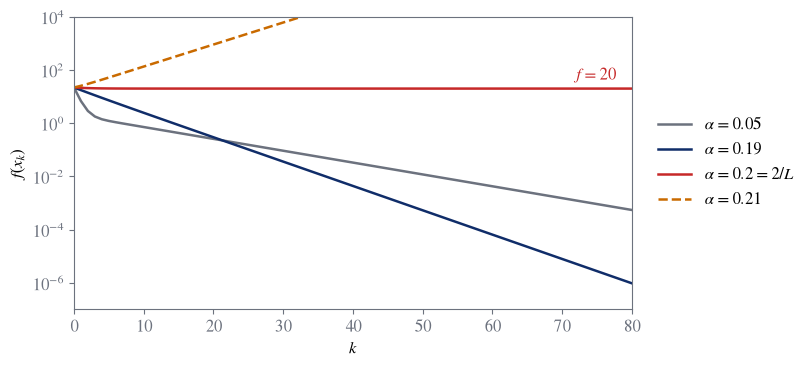

In [22]:
K = 80
fig, ax = plt.subplots(figsize=(7.2, 3.8))
styles = [(HSE["gray"], "-"), (HSE["blue"], "-"), (HSE["accent"], "-"), (HSE["orange"], "--")]
for a, (color, ls) in zip(A1_alphas, styles):
    label = rf"$\alpha={float(a):g}" + ("=2/L$" if a == 2 / L_A1 else "$")
    ax.plot(range(K + 1), runs[a]["f"][:K + 1], color=color, ls=ls, lw=1.8, label=label)
ax.set_yscale("log")
ax.set_xlim(0, K)
ax.set_ylim(1e-7, 1e4)
ax.annotate(r"$f=20$", (K, float(stall)), textcoords="offset points", xytext=(-40, 6), color=HSE["accent"])
ax.set_xlabel("$k$")
ax.set_ylabel(r"$f(x_k)$")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5))
save(fig, "fig_stability")
plt.show()

### Conditioning at $\alpha=1/L$

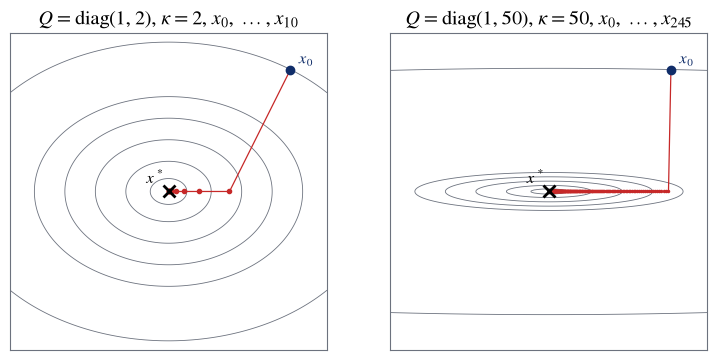

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
ext = (-1.3, 1.3, -1.3, 1.3)
X, Y = np.meshgrid(np.linspace(ext[0], ext[1], 320), np.linspace(ext[2], ext[3], 320))
for ax, pid in zip(axes, ("A2", "A3")):
    lam, x0 = PUB[pid]["params"]["lam"], PUB[pid]["params"]["x0"]
    f, grad = quadratic(lam)
    n_obs = STU[pid]["observed"]
    _, hist = gradient_descent(f, grad, x0, step=1 / max(lam), tol=0.0, max_iter=n_obs)
    path = np.array(hist["x"])
    Z = 0.5 * (lam[0] * X**2 + lam[1] * Y**2)
    levels = sorted({0.5 * r * r for r in (0.15, 0.35, 0.6, 0.85, 1.1)} | {f(np.array(x0, dtype=float))})
    ax.contour(X, Y, Z, levels=levels, colors=[HSE["gray"]], linewidths=0.6)
    ax.plot(path[:, 0], path[:, 1], "-", color=HSE["accent"], lw=0.9)
    ax.plot(path[:, 0], path[:, 1], "o", color=HSE["accent"], ms=3 if n_obs < 50 else 1.5)
    ax.plot(*path[0], "o", color=HSE["blue"], ms=6)
    ax.plot(0, 0, "x", color="black", ms=8, mew=2)
    ax.annotate(r"$x_0$", path[0], textcoords="offset points", xytext=(6, 4), color=HSE["blue"])
    ax.annotate(r"$x^*$", (0, 0), textcoords="offset points", xytext=(-16, 6))
    ax.set_xlim(ext[0], ext[1])
    ax.set_ylim(ext[2], ext[3])
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    kap = max(lam) // min(lam)
    ax.set_title(rf"$Q=\mathrm{{diag}}({lam[0]},{lam[1]})$, $\kappa={kap}$, $x_0,\dots,x_{{{n_obs}}}$")
save(fig, "fig_conditioning")
plt.show()

### Error of the central difference

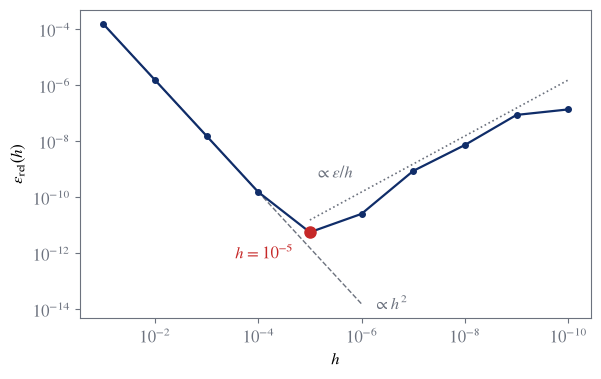

In [24]:
eps = np.finfo(float).eps
h = np.array(D3_h)
round_off = eps * abs(z_c1(2.0, -1.0)) / (h * abs(exact))
fig, ax = plt.subplots(figsize=(6.6, 4.0))
ax.loglog(h[:6], np.array(truncation[:6]), ls="--", color=HSE["gray"], lw=1)
ax.loglog(h[4:], round_off[4:], ls=":", color=HSE["gray"], lw=1.2)
ax.loglog(h, D3_err, "o-", color=HSE["blue"], ms=4, lw=1.6)
ax.plot(h[best], D3_err[best], "o", color=HSE["accent"], ms=8)
ax.annotate(rf"$h=10^{{{-D3_k[best]}}}$", (h[best], D3_err[best]), textcoords="offset points",
            xytext=(-12, -8), color=HSE["accent"], ha="right", va="top")
ax.annotate(r"$\propto h^2$", (h[5], truncation[5]), textcoords="offset points", xytext=(8, 0),
            color=HSE["gray"], va="center")
ax.annotate(r"$\propto \varepsilon/h$", (h[5], round_off[5]), textcoords="offset points", xytext=(-6, 10),
            color=HSE["gray"], ha="right")
ax.invert_xaxis()
ax.set_xlabel("$h$")
ax.set_ylabel(r"$\varepsilon_{\mathrm{rel}}(h)$")
save(fig, "fig_fd_error")
plt.show()

### The graph of C1

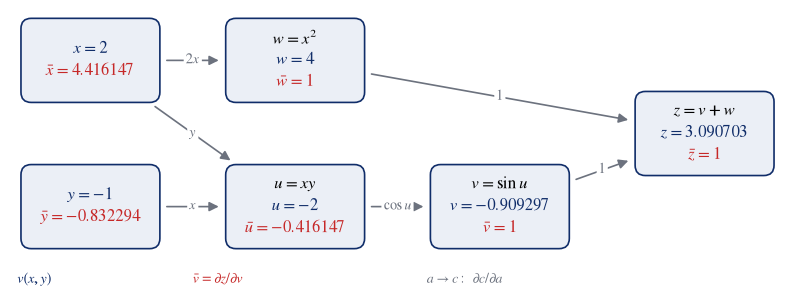

In [25]:
x, y = 2.0, -1.0
NODES = {
    "x": ((0.0, 2.0), None, "2", s6(C1_grad[0])),
    "y": ((0.0, 0.0), None, "-1", s6(C1_grad[1])),
    "w": ((2.8, 2.0), r"$w=x^2$", "4", "1"),
    "u": ((2.8, 0.0), r"$u=xy$", "-2", s6(math.cos(x * y))),
    "v": ((5.6, 0.0), r"$v=\sin u$", s6(math.sin(x * y)), "1"),
    "z": ((8.4, 1.0), r"$z=v+w$", s6(z_c1(x, y)), "1"),
}
EDGES = [("x", "w", "$2x$"), ("x", "u", "$y$"), ("y", "u", "$x$"), ("u", "v", r"$\cos u$"),
         ("v", "z", "$1$"), ("w", "z", "$1$")]
BOX_W, BOX_H = 1.9, 1.15


def border(p, q):
    """The point where the segment from the centre p towards q leaves the box around p."""
    d = np.subtract(q, p)
    s = min(BOX_W / 2 / abs(d[0]) if d[0] else np.inf, BOX_H / 2 / abs(d[1]) if d[1] else np.inf)
    return np.add(p, 1.06 * s * d)


fig, ax = plt.subplots(figsize=(10, 4.0))
for name, ((cx, cy), head, value, adjoint) in NODES.items():
    ax.add_patch(FancyBboxPatch((cx - BOX_W / 2, cy - BOX_H / 2), BOX_W, BOX_H,
                                boxstyle="round,pad=0,rounding_size=0.14",
                                facecolor=HSE["light"], edgecolor=HSE["blue"], lw=1.2))
    # an input has no definition line, its value and adjoint sit in the middle
    if head is not None:
        ax.text(cx, cy + 0.3, head, ha="center", va="center", color="black")
    shift = 0.0 if head is not None else 0.15
    ax.text(cx, cy + shift, rf"${name}={value}$", ha="center", va="center", color=HSE["blue"])
    ax.text(cx, cy - 0.3 + shift, rf"$\bar{{{name}}}={adjoint}$", ha="center", va="center", color=HSE["accent"])
for a, b, label in EDGES:
    p, q = NODES[a][0], NODES[b][0]
    ax.add_patch(FancyArrowPatch(border(p, q), border(q, p), arrowstyle="-|>", mutation_scale=14,
                                 color=HSE["gray"], lw=1.2))
    mid = (np.add(p, q)) / 2
    ax.text(*mid, label, ha="center", va="center", fontsize=10, color=HSE["gray"],
            bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none"))
ax.text(-1.0, -1.05, r"$v(x,y)$", color=HSE["blue"], fontsize=10)
ax.text(1.4, -1.05, r"$\bar{v}=\partial z/\partial v$", color=HSE["accent"], fontsize=10)
ax.text(4.6, -1.05, r"$a\to c:\ \partial c/\partial a$", color=HSE["gray"], fontsize=10)
ax.set_xlim(-1.1, 9.5)
ax.set_ylim(-1.25, 2.7)
ax.set_aspect("equal")
ax.axis("off")
save(fig, "fig_graph_c1")
plt.show()

## 13. Theory handout and cheat sheet

`Theory_en.tex`, `Theory_ru.tex`, `Cheatsheet_en.tex` and `Cheatsheet_ru.tex` are generated from the students' content merged over the public one, as the page merges them. The numbers are written into the text with at most four decimals, with a decimal comma in Russian.

In [26]:
TOKEN = re.compile(r"\{\{\s*([A-Za-z0-9.]+)\s*\}\}")


def merge_over(target, overlay):
    """The merge of access.js: objects key by key, arrays element by element, anything else replaced."""
    for key, b in overlay.items():
        a = target.get(key)
        if isinstance(a, dict) and isinstance(b, dict):
            merge_over(a, b)
        elif isinstance(a, list) and isinstance(b, list):
            for i, item in enumerate(b):
                if i < len(a) and isinstance(a[i], dict) and isinstance(item, dict):
                    merge_over(a[i], item)
                elif i < len(a):
                    a[i] = copy.deepcopy(item)
                else:
                    a.append(copy.deepcopy(item))
        else:
            target[key] = copy.deepcopy(b)
    return target


def value_at(data, path):
    node = at(data, path)
    if node is MISSING or node is None or isinstance(node, dict):
        raise KeyError(f"unresolved token {path}")
    return node


def is_num(v):
    return isinstance(v, (int, float)) and not isinstance(v, bool)


def decimal_str(v, digits=4):
    # toFixed of JavaScript: a tie goes away from zero
    s = str(Decimal(v).quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))
    if "." in s:
        s = s.rstrip("0").rstrip(".")
    return "0" if s == "-0" else s


def tex_num(v, lang, math):
    s = decimal_str(v)
    if math:
        return s.replace(".", "{,}") if lang == "ru" else s
    s = s.replace(".", ",") if lang == "ru" else s
    return "\u2212" + s[1:] if s.startswith("-") else s


def tex_value(v, lang, math):
    """render.value of render.js: a data value as TeX (math) or as text."""
    if is_num(v):
        return tex_num(v, lang, math)
    if isinstance(v, str):
        if math:
            return re.sub(r"(\d)\.(\d)", r"\1{,}\2", v).replace(r",\ ", r";\ ") if lang == "ru" else v
        if lang == "ru" and re.fullmatch(r"-?\d+\.\d+", v):
            v = v.replace(".", ",")
        return "\u2212" + v[1:] if lang == "ru" and v.startswith("-") else v
    if isinstance(v, list) and v and all(is_num(x) for x in v):
        sep = (r";\ " if lang == "ru" else r",\ ") if math else ("; " if lang == "ru" else ", ")
        return "(" + sep.join(tex_num(x, lang, math) for x in v) + ")"
    if isinstance(v, list) and v and all(isinstance(r, list) and r and all(is_num(x) for x in r) for r in v):
        if not math:
            return " ".join(tex_value(r, lang, False) for r in v)
        rows = r" \\ ".join(" & ".join(tex_num(x, lang, True) for x in r) for r in v)
        return r"\begin{pmatrix} " + rows + r" \end{pmatrix}"
    return None


def tex_token(path, data, lang, math):
    v = value_at(data, path)
    tex = tex_value(v, lang, True)
    assert tex is not None, path
    if math:
        return tex
    text = tex_value(v, lang, False)
    # a plain nonnegative number stays text; anything with a sign or TeX goes into math
    return text if re.fullmatch(r"[0-9.,]+", text) else "$" + tex + "$"


def tex_segments(s):
    """The segmenter of render.js: $$display$$, $inline$, \\$ a literal dollar, text; a lone $ is text."""
    out, buf, i = [], "", 0
    while i < len(s):
        ch = s[i]
        if ch == "\\" and s[i + 1 : i + 2] == "$":
            buf += "\x03"
            i += 2
            continue
        if ch == "$":
            display = s[i + 1 : i + 2] == "$"
            n = 2 if display else 1
            close = s.find("$$" if display else "$", i + n)
            if close < 0:
                buf += s[i:]
                break
            if buf:
                out.append(("text", buf))
            buf = ""
            out.append(("display" if display else "math", s[i + n : close]))
            i = close + n
            continue
        buf += ch
        i += 1
    if buf:
        out.append(("text", buf))
    return out


ESC = [("{", r"\{"), ("}", r"\}"), ("%", r"\%"), ("&", r"\&"), ("#", r"\#"), ("_", r"\_"),
       ("~", r"\textasciitilde{}"), ("^", r"\textasciicircum{}")]


def esc(text):
    text = text.replace("\\", "\x00")
    for a, b in ESC:
        text = text.replace(a, b)
    return text.replace("\x00", r"\textbackslash{}")


def rich(s, data, lang):
    """One content string as LaTeX: tokens become numbers and the markup \\textbf, \\emph, \\texttt."""
    # displays with only spaces between them are stacked in one: two \[ \] in a row leave an empty line
    segs = []
    for kind, seg in tex_segments(s):
        if kind == "display" and len(segs) > 1 and segs[-2][0] == "display" and segs[-1][0] == "text" \
                and not segs[-1][1].strip():
            segs.pop()
        if kind == "display" and segs and segs[-1][0] == "display":
            segs[-1][1].append(seg)
        else:
            segs.append((kind, [seg] if kind == "display" else seg))
    parts = []
    for kind, seg in segs:
        if kind == "display":
            lines = " \\\\[6pt]\n".join(b.strip() for b in seg)
            seg = lines if len(seg) == 1 else "\\begin{gathered}\n" + lines + "\n\\end{gathered}"
        if kind in ("math", "display"):
            body = TOKEN.sub(lambda m: tex_token(m.group(1), data, lang, True), seg)
            body = body.replace("\u00a0", " ").replace("\u202f", r"\,")
            assert "%" not in body and "#" not in body and "{{" not in body, seg
            display = "\n\\handoutdisplay{\n" + body.strip() + "\n}\n"
            parts.append("$" + body + "$" if kind == "math" else display)
            continue
        # tokens and code spans are set aside before escaping and restored after the markup
        toks, codes = [], []
        t = TOKEN.sub(lambda m: toks.append(m.group(1)) or f"\x01{len(toks) - 1}\x01", seg)
        t = re.sub(r"`([^`]+)`", lambda m: codes.append(esc(m.group(1))) or f"\x02{len(codes) - 1}\x02", t)
        t = esc(t).replace("\x03", r"\$").replace("\u00a0", "~").replace("\u202f", r"\,")
        t = re.sub(r"\*\*([^*]+)\*\*", r"\\textbf{\1}", t)
        t = re.sub(r"\*([^*\s][^*]*)\*", r"\\emph{\1}", t)
        t = re.sub("\x02(\\d+)\x02", lambda m: r"\texttt{" + codes[int(m.group(1))] + "}", t)
        t = re.sub("\x01(\\d+)\x01", lambda m: tex_token(toks[int(m.group(1))], data, lang, False), t)
        parts.append(t)
    out = "".join(parts)
    assert not re.search("[\x00-\x03\u00a0]", out), s
    return out


def tr(pair, data, lang, inline=False):
    """A pair as LaTeX; while a Russian string is missing, the English one is set with English hyphenation."""
    if pair.get(lang):
        return rich(pair[lang], data, lang)
    tex = rich(pair["en"], data, "en")
    if lang == "en":
        return tex
    return "\\textenglish{" + tex + "}" if inline else "\\begin{english}\n" + tex + "\n\\end{english}"


def cell_kind(cell):
    segs = tex_segments(cell)
    if len(segs) == 1 and segs[0][0] == "math":
        body = TOKEN.sub("v", segs[0][1]).strip()
        if re.fullmatch(r"v|-?\d+(\.\d+)?", body):
            return "num"
    if all(k != "text" or re.fullmatch(r"[\s,]*", v) for k, v in segs):
        return "math"
    return "text"


def cell_width(cell, data, lang):
    """Printed width of a table cell in characters; a TeX command counts as one, braces as none."""
    w = 0
    for kind, seg in tex_segments(cell):
        if kind == "text":
            seg = TOKEN.sub(lambda m: tex_value(value_at(data, m.group(1)), lang, False), seg)
            w += len(seg.replace("**", "").replace("*", "").replace("`", ""))
        else:
            body = TOKEN.sub(lambda m: tex_token(m.group(1), data, lang, True), seg)
            body = re.sub(r"\\[A-Za-z]+|\\.", "c", body).replace("{", "").replace("}", "")
            w += 2 + len(body)
    return w


# room the paragraph columns must leave: a character of a column that keeps its natural width takes at
# most this fraction of the 466.6pt text width at \small, and 2\tabcolsep between two columns takes 12pt
CHAR_SHARE = {"text": 0.012, "math": 0.010, "num": 0.010}
GAP_SHARE = 0.026


def table_spec(head, rows, data, lang):
    ncol = len(head)
    kinds, widths = [], []
    for j in range(ncol):
        body = [r[j] for r in rows]
        ks = {cell_kind(c) for c in body}
        kinds.append("num" if ks == {"num"} else "math" if ks <= {"num", "math"} else "text")
        widths.append(max(cell_width(c, data, lang) for c in [head[j]] + body))
    total = sum(widths)
    spec = ["r" if k == "num" else "l" for k in kinds]
    # a wide table gets paragraph columns for its long text columns, or for its widest column
    if total > 70:
        wide = [j for j in range(ncol) if kinds[j] == "text" and widths[j] >= 18]
        if wide:
            shares = {j: 0.9 * widths[j] / total for j in wide}
        else:
            wide = [max(range(ncol), key=lambda k: widths[k])]
            shares = {wide[0]: 0.4}
        natural = sum(CHAR_SHARE[kinds[j]] * widths[j] for j in range(ncol) if j not in wide)
        budget = 0.98 - GAP_SHARE * (ncol - 1) - natural
        # the fractions are scaled into the budget and rounded down, so their sum plus the natural
        # columns stays inside \linewidth however the estimate of the natural ones errs; a column raised
        # to the floor of 0.15 takes its room from the others
        scale = min(1.0, budget / sum(shares.values()))
        low = [j for j in wide if shares[j] * scale < 0.15]
        high = sum(shares[j] for j in wide if j not in low) * scale
        squeeze = min(1.0, (budget - 0.15 * len(low)) / high) if high else 1.0
        for j in wide:
            share = f"{0.15 if j in low else int(100 * shares[j] * scale * squeeze) / 100:g}"
            # \hspace{0pt} lets the first word of a cell be hyphenated
            spec[j] = r">{\raggedright\arraybackslash\hspace{0pt}}p{" + share + r"\linewidth}"
    return "@{}" + "".join(spec) + "@{}"


def table_tex(block, data, lang):
    pick = lambda c: c.get(lang) or c["en"]
    head, rows = [pick(c) for c in block["head"]], [[pick(c) for c in row] for row in block["rows"]]
    spec = table_spec(head, rows, data, lang)
    line = lambda cells: " & ".join(tr(c, data, lang, inline=True) for c in cells) + r" \\"
    body = [line(r) for r in block["rows"]]
    if len(body) > 10:
        return "\n".join([r"\begingroup\small", r"\begin{longtable}{" + spec + "}", r"\toprule",
                          line(block["head"]), r"\midrule", r"\endhead", *body, r"\bottomrule",
                          r"\end{longtable}", r"\endgroup"])
    return "\n".join([r"\begin{center}\small", r"\begin{tabular}{" + spec + "}", r"\toprule",
                      line(block["head"]), r"\midrule", *body, r"\bottomrule", r"\end{tabular}",
                      r"\end{center}"])


FIG_WIDTH = {"fig_stability": 0.9, "fig_conditioning": 0.95, "fig_graph_c1": 0.95, "fig_fd_error": 0.72}
LABELS = {
    "en": {"course": "Optimization Methods", "seminar": "Seminar 03", "page": "Theory handout",
           "topic": "Gradient Descent and Automatic Differentiation",
           "institution": "HSE University, Faculty of Computer Science", "year": "Academic year 2026–2027",
           "lecturer": "Course lecturer: Andrey Ignatov", "author": "Evgeny Baulin",
           "byline": "Author: Evgeny Baulin", "license": "MIT License", "kicker": "Seminar 03 cheat sheet",
           "definition": "Definition", "theorem": "Theorem", "lemma": "Lemma", "corollary": "Corollary",
           "proposition": "Proposition", "proof": "Proof", "example": "Example", "intuition": "Why",
           "trap": "Trap", "selfcheck": "Check yourself", "answer": "Answer", "convention": "Notation",
           "figure": "Figure", "statement": "Statement", "solution": "Solution",
           "board": "On the board", "students": "On your own"},
    "ru": {"course": "Методы оптимизации", "seminar": "Семинар 3", "page": "Конспект теории",
           "topic": "Градиентный спуск и автоматическое дифференцирование",
           "institution": "НИУ ВШЭ, факультет компьютерных наук", "year": "2026–2027 учебный год",
           "lecturer": "Лектор курса: Андрей Игнатов", "author": "Евгений Баулин",
           "byline": "Автор: Евгений Баулин", "license": "Лицензия MIT", "kicker": "Шпаргалка к семинару 3",
           "definition": "Определение", "theorem": "Теорема", "lemma": "Лемма", "corollary": "Следствие",
           "proposition": "Утверждение", "proof": "Доказательство", "example": "Пример",
           "intuition": "Почему",
           "trap": "Ловушка", "selfcheck": "Проверьте себя", "answer": "Ответ", "convention": "Обозначения",
           "figure": "Рисунок", "statement": "Условие", "solution": "Решение",
           "board": "У доски", "students": "Самостоятельно"},
}


def period(s):
    return s if s.endswith((".", "?", "!")) else s + "."


def block_tex(b, content, data, lang):
    t, L = b["type"], LABELS[lang]
    text = lambda pair: tr(pair, data, lang)
    title = lambda pair: tr(pair, data, lang, inline=True)
    if t == "p":
        return text(b["text"])
    if t in ("example", "intuition"):
        env = "examplebox" if t == "example" else "whybox"
        return f"\\begin{{{env}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t == "list":
        items = "\n".join("  \\item " + text(i) for i in b["items"])
        return "\\begin{itemize}\n" + items + "\n\\end{itemize}"
    if t == "figure":
        name = re.fullmatch(r"(?:figures/)?(fig_[a-z0-9_]+)(?:\.svg)?", b["src"]).group(1)
        cap = text(b["caption"]) if b.get("caption") else ""
        return f"\\handoutfigure{{{FIG_WIDTH[name]:g}}}{{{name}}}{{{cap}}}"
    if t == "table":
        return table_tex(b, data, lang)
    if t in ("definition", "theorem"):
        kind = "definition" if t == "definition" else b.get("kind", "theorem")
        label = L[kind] + (": " + title(b["title"]) if b.get("title") else "")
        env = "definitionbox" if t == "definition" else "theorembox"
        return f"\\begin{{{env}}}{{{period(label)}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t in ("proof", "trap"):
        env = t + "box"
        return f"\\begin{{{env}}}\n{text(b['text'])}\n\\end{{{env}}}"
    if t == "note":
        return f"\\begin{{notebox}}{{{title(b['title'])}}}\n{text(b['text'])}\n\\end{{notebox}}"
    if t == "selfcheck":
        return (f"\\begin{{selfcheckbox}}\n{text(b['question'])}\n"
                f"\\selfcheckanswer {text(b['answer'])}\n\\end{{selfcheckbox}}")
    if t == "problem":
        return problem_tex(b["id"], content, data, lang)
    raise ValueError(f"unknown block type {t}")


def problem_tex(pid, content, data, lang):
    P, L = content["problems"][pid], LABELS[lang]
    steps = ["  \\item " + tr(st["text"], data, lang) for st in P["steps"]]
    return "\n".join([
        f"\\problemhead{{{pid}}}{{{tr(P['title'], data, lang, inline=True)}}}{{{L[P['who']]}}}",
        f"\\textbf{{{L['statement']}.}} {tr(P['statement'], data, lang)}",
        "",
        f"\\textbf{{{L['solution']}.}}",
        # a step quotes numbers that cannot be hyphenated: let the spaces stretch instead
        "\\begingroup\\sloppy",
        "\\begin{enumerate}[label=\\textbf{\\arabic*.}, leftmargin=*]",
        *steps,
        "\\end{enumerate}",
        "\\endgroup",
        "\\begin{answerbox}",
        tr(P["answerText"], data, lang),
        "\\end{answerbox}",
    ])


def fill(template, values):
    for name, tex in values.items():
        placeholder = f"<<{name}>>"
        assert template.count(placeholder) == 1, name
        template = template.replace(placeholder, tex)
    assert "<<" not in template
    return template


def tidy(doc):
    """No trailing spaces: a text segment before a display keeps the space it ended with."""
    return "\n".join(line.rstrip() for line in doc.split("\n"))


LANGUAGE_SETUP = {
    "en": r"""\usepackage{polyglossia}
\setdefaultlanguage{english}""",
    "ru": r"""\usepackage{polyglossia}
\setdefaultlanguage{russian}
\setotherlanguage{english}
\newfontfamily\cyrillicfont{cmunrm.otf}[Ligatures=TeX, BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\newfontfamily\cyrillicfontsf{cmunss.otf}[Ligatures=TeX, BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\newfontfamily\cyrillicfonttt{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]""",
}

THEORY_PREAMBLE = r"""% SPDX-License-Identifier: MIT
% Copyright (c) 2026 Evgeny Baulin
% Optimization Methods, Seminar 03: theory handout (<<language>>).
% Generated by checks/03. Gradient Descent and Automatic Differentiation.ipynb from web/03/js/content-*.js and content/students.json. Do not edit by hand.
% Compile with: latexmk -xelatex -interaction=nonstopmode -halt-on-error <<file>>.tex
\documentclass[11pt,a4paper]{article}

\usepackage{fontspec}
\setmainfont{cmunrm.otf}[BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\setsansfont{cmunss.otf}[BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\setmonofont{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]
<<languageSetup>>

\usepackage[a4paper,left=2.3cm,right=2.3cm,top=2.4cm,bottom=2.4cm,headheight=14pt]{geometry}
\usepackage{amsmath,amssymb}
\usepackage{graphicx}
\usepackage{array,booktabs,longtable}
\usepackage{enumitem}
\usepackage{xcolor}
\usepackage[most]{tcolorbox}
\usepackage{titlesec}
\usepackage{fancyhdr}
\usepackage{needspace}
\usepackage[expansion=false]{microtype}
\usepackage[colorlinks=true,linkcolor=hseblue,urlcolor=hseblue,citecolor=hseblue]{hyperref}

\definecolor{hseblue}{RGB}{16,45,105}
\definecolor{hseaccent}{RGB}{198,40,40}
\definecolor{hsegray}{RGB}{108,114,126}
\definecolor{hselight}{RGB}{240,243,248}
\definecolor{hsewarm}{RGB}{253,244,232}

\hypersetup{pdftitle={<<pdftitle>>}, pdfauthor={<<pdfauthor>>}}

\titleformat{\section}{\color{hseblue}\Large\bfseries}{\thesection}{0.6em}{}
\titleformat{\subsection}{\color{hseblue}\large\bfseries}{\thesubsection}{0.6em}{}
\titlespacing*{\section}{0pt}{16pt plus 4pt minus 2pt}{8pt plus 2pt}
\titlespacing*{\subsection}{0pt}{12pt plus 3pt minus 2pt}{6pt plus 2pt}
% a heading keeps a few lines under it on its page: a breakable box right after it would otherwise leave it alone
\pretocmd{\section}{\Needspace{7\baselineskip}}{}{\errmessage{cannot patch section}}
\pretocmd{\subsection}{\Needspace{5\baselineskip}}{}{\errmessage{cannot patch subsection}}

\tcbset{handoutbox/.style={enhanced, breakable, sharp corners, boxrule=0pt, left=7pt, right=7pt, top=5pt, bottom=5pt, before skip=8pt plus 2pt, after skip=8pt plus 2pt}}
\newtcolorbox{examplebox}{handoutbox, colback=hselight, colframe=hselight, before upper={\textcolor{hseblue}{\bfseries <<labelExample>>}\ }}
\newtcolorbox{whybox}{handoutbox, colback=white, colframe=hseblue, leftrule=2.5pt, top=3pt, bottom=3pt, before upper={\textcolor{hseaccent}{\bfseries <<labelWhy>>}\ }}
\newtcolorbox{answerbox}{handoutbox, colback=hsewarm, colframe=hsewarm, before upper={\textcolor{hseaccent}{\bfseries <<labelAnswer>>}\ }}
\newtcolorbox{conventionbox}{handoutbox, colback=hselight, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries <<labelConvention>>}\par\smallskip}}

\newcommand{\handoutfigure}[3]{\par\medskip\noindent\begin{minipage}{\linewidth}\centering
  \includegraphics[width=#1\linewidth]{figures/#2.pdf}\par\smallskip
  \begin{minipage}{0.94\linewidth}\small\textcolor{hseblue}{\bfseries <<labelFigure>>}\ #3\end{minipage}\end{minipage}\par\medskip}
\newcommand{\problemhead}[3]{\par\bigskip\noindent{\color{hseblue}\large\bfseries #1.\ #2}\par\nopagebreak
  \noindent{\small\itshape\color{hsegray}#3}\par\nopagebreak\smallskip}
\newtcolorbox{definitionbox}[1]{handoutbox, colback=white, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries #1}\ }}
\newtcolorbox{theorembox}[1]{handoutbox, colback=hselight, colframe=hseblue, leftrule=2.5pt, before upper={\textcolor{hseblue}{\bfseries #1}\ }}
\newtcolorbox{proofbox}{handoutbox, colback=white, colframe=hsegray, leftrule=1.2pt, top=3pt, bottom=3pt, before upper={\textcolor{hsegray}{\bfseries\itshape <<labelProof>>}\ }}
\newtcolorbox{notebox}[1]{handoutbox, colback=hselight, colframe=hselight, before upper={\textcolor{hseblue}{\bfseries #1}\par\smallskip}}
\newtcolorbox{trapbox}{handoutbox, colback=hsewarm, colframe=hseaccent, leftrule=2.5pt, before upper={\textcolor{hseaccent}{\bfseries <<labelTrap>>}\ }}
\newtcolorbox{selfcheckbox}{handoutbox, colback=white, colframe=hseaccent, leftrule=2.5pt, top=3pt, bottom=3pt, before upper={\textcolor{hseaccent}{\bfseries <<labelSelfcheck>>}\ }}
% a display wider than the line is set as a centred paragraph that may break after a relation
\newcommand{\handoutdisplay}[1]{\sbox0{$\displaystyle #1$}\ifdim\wd0>\linewidth
  \par{\centering\binoppenalty=10000\relpenalty=0\relax$\displaystyle #1$\par}\else\[#1\]\fi}
\newcommand{\selfcheckanswer}{\par\smallskip\textcolor{hsegray}{\bfseries <<labelSelfcheckAnswer>>}\ }

\setlist[itemize]{itemsep=3pt,topsep=4pt}
\setlist[enumerate]{itemsep=3pt,topsep=4pt}
\setlength{\parindent}{0pt}
\setlength{\parskip}{5pt plus 1pt}
\setlength{\emergencystretch}{2em}
\setcounter{tocdepth}{2}

\pagestyle{fancy}
\fancyhf{}
\fancyhead[L]{\small\color{hsegray}<<headerCourse>>}
\fancyhead[R]{\small\color{hsegray}<<headerSeminar>>}
\fancyfoot[L]{\small\color{hsegray}<<footerAuthor>>}
\fancyfoot[C]{\small\thepage}
\fancyfoot[R]{\small\color{hsegray}<<footerLicense>>}
\renewcommand{\headrulewidth}{0pt}
\renewcommand{\footrulewidth}{0pt}
\fancypagestyle{plain}{\pagestyle{fancy}}

\begin{document}

\begin{center}
  {\large\color{hsegray}<<titleCourse>>\par}
  \vspace{4pt}
  {\large\bfseries\color{hseaccent}<<titleSeminar>>\par}
  \vspace{8pt}
  {\LARGE\bfseries\color{hseblue}<<titleTopic>>\par}
  \vspace{8pt}
  {\Large <<titlePage>>\par}
  \vspace{12pt}
  <<titleInstitution>>\par
  <<titleYear>>\par
  \vspace{8pt}
  <<titleLecturer>>\par
  <<titleAuthor>>\par
  Telegram: \href{https://t.me/tarakan_tuc}{@tarakan\_tuc}\par
\end{center}

\noindent{\color{hseblue}\rule{\linewidth}{0.6pt}}

\tableofcontents

\clearpage
"""

CHEAT_PREAMBLE = r"""% SPDX-License-Identifier: MIT
% Copyright (c) 2026 Evgeny Baulin
% Optimization Methods, Seminar 03: one-page cheat sheet (<<language>>).
% Generated by checks/03. Gradient Descent and Automatic Differentiation.ipynb from web/03/js/content-cheatsheet.js and content/students.json. Do not edit by hand.
% Compile with: latexmk -xelatex -interaction=nonstopmode -halt-on-error <<file>>.tex
\RequirePackage{fix-cm}
\documentclass[10pt,a4paper]{article}

\usepackage{amsmath,amssymb}
\usepackage{fontspec}
\setmainfont{cmunrm.otf}[BoldFont=cmunbx.otf, ItalicFont=cmunti.otf, BoldItalicFont=cmunbi.otf]
\setsansfont{cmunss.otf}[BoldFont=cmunsx.otf, ItalicFont=cmunsi.otf, BoldItalicFont=cmunso.otf]
\setmonofont{cmuntt.otf}[BoldFont=cmuntb.otf, ItalicFont=cmunit.otf, BoldItalicFont=cmuntx.otf]
<<languageSetup>>

\usepackage[a4paper,left=8mm,right=8mm,top=7mm,bottom=11mm,footskip=5.5mm]{geometry}
\usepackage{xcolor}
\usepackage{multicol}
\usepackage{enumitem}
\usepackage{ragged2e}
\usepackage{fancyhdr}
\usepackage[colorlinks=true,linkcolor=hseblue,urlcolor=hseblue]{hyperref}

\definecolor{hseblue}{RGB}{16,45,105}
\definecolor{hseaccent}{RGB}{198,40,40}
\definecolor{hsegray}{RGB}{108,114,126}
\definecolor{hselight}{RGB}{240,243,248}

\hypersetup{pdftitle={<<pdftitle>>}, pdfauthor={<<pdfauthor>>}}

% Page style: the author and the license in the footer.
\pagestyle{fancy}
\fancyhf{}
\renewcommand{\headrulewidth}{0pt}
\fancyfoot[L]{\scriptsize\color{hsegray}\textcopyright\ 2026 <<footerAuthor>>, \href{https://t.me/tarakan_tuc}{t.me/tarakan\_tuc}}
\fancyfoot[R]{\scriptsize\color{hsegray}<<footerLicense>>}

% Compact layout.
\setlength{\parindent}{0pt}
\setlength{\parskip}{0pt}
\setlength{\columnsep}{4.5mm}
\setlength{\columnseprule}{0.3pt}
\renewcommand{\columnseprulecolor}{\color{hselight}}
\setlength{\emergencystretch}{2em}
\setlength{\RaggedRightRightskip}{0pt plus 4em}
\binoppenalty=2000
\relpenalty=500
\setlength{\abovedisplayskip}{2pt}
\setlength{\belowdisplayskip}{2pt}
\setlist[itemize]{leftmargin=7pt, labelsep=3pt, itemsep=1.2pt, topsep=1pt, parsep=0pt, partopsep=0pt,
  label={\color{hseaccent}\scriptsize\textbullet}}

\makeatletter
\newcommand{\cssec}[1]{\par\addvspace{3.5pt}\noindent
  \colorbox{hselight}{\parbox{\dimexpr\linewidth-2\fboxsep}{\RaggedRight\hyphenpenalty=10000\color{hseblue}\bfseries\strut #1}}%
  \par\nobreak\vspace{1pt}\@afterheading}
\makeatother
\clubpenalty=10000
\widowpenalty=10000

\begin{document}
\thispagestyle{fancy}

\noindent
\begin{minipage}[b]{0.6\textwidth}
  \RaggedRight\hyphenpenalty=10000
  {\color{hseaccent}\bfseries\small <<kicker>>}\\[1pt]
  {\color{hseblue}\bfseries\Large <<title>>}
\end{minipage}\hfill
\begin{minipage}[b]{0.39\textwidth}
  \raggedleft\footnotesize
  {\bfseries <<course>>}\\
  <<institution>>, 2026--2027\\
  <<lecturer>>\\
  <<byline>>, Telegram \href{https://t.me/tarakan_tuc}{@tarakan\_tuc}
\end{minipage}

\vspace{2pt}
{\color{hseblue}\rule{\textwidth}{0.8pt}}
\vspace{-4pt}

\fontsize{9}{<<leading>>}\selectfont
\begin{multicols}{3}
\RaggedRight
"""


def theory_tex(lang, content, data):
    h, L = content["handout"], LABELS[lang]
    topic = h["title"][lang] if h["title"].get(lang) else L["topic"]
    values = {
        "language": {"en": "English", "ru": "Russian"}[lang],
        "file": f"Theory_{lang}",
        "languageSetup": LANGUAGE_SETUP[lang],
        "pdftitle": esc(f"{L['course']}. {L['seminar']}. {L['page']}"),
        "pdfauthor": esc(L["author"]),
        "labelExample": period(L["example"]),
        "labelWhy": period(L["intuition"]),
        "labelAnswer": period(L["answer"]),
        "labelConvention": period(L["convention"]),
        "labelFigure": period(L["figure"]),
        "labelProof": period(L["proof"]),
        "labelTrap": period(L["trap"]),
        "labelSelfcheck": period(L["selfcheck"]),
        "labelSelfcheckAnswer": period(L["answer"]),
        "headerCourse": esc(L["course"]),
        "headerSeminar": esc(L["seminar"]),
        "footerAuthor": esc(L["author"]),
        "footerLicense": esc(L["license"]),
        "titleCourse": esc(L["course"]),
        "titleSeminar": esc(L["seminar"]),
        "titleTopic": rich(topic, data, lang),
        "titlePage": esc(L["page"]),
        "titleInstitution": esc(L["institution"]),
        "titleYear": esc(L["year"]),
        "titleLecturer": esc(L["lecturer"]),
        "titleAuthor": esc(L["author"]),
    }
    out = [fill(THEORY_PREAMBLE, values), "", tr(h["intro"], data, lang), "",
           "\\begin{conventionbox}", tr(h["convention"], data, lang), "\\end{conventionbox}", ""]
    for sec in h["sections"]:
        heading = tr(sec["title"], data, lang, inline=True)
        out += ["% " + "=" * 69, f"\\section{{{heading}}}\\label{{sec:{sec['id']}}}", ""]
        for b in sec.get("blocks", []):
            out += [block_tex(b, content, data, lang), ""]
        for sub in sec.get("subsections", []):
            heading = tr(sub["title"], data, lang, inline=True)
            out += [f"\\subsection{{{heading}}}\\label{{sub:{sub['id']}}}", ""]
            for b in sub.get("blocks", []):
                out += [block_tex(b, content, data, lang), ""]
    out.append("\\end{document}")
    return tidy("\n".join(out)) + "\n"


def split_title(title):
    """Two lines, broken at the space nearest to the middle that does not follow a short word."""
    spaces = [i for i, ch in enumerate(title) if ch == " " and len(title[:i].split(" ")[-1]) > 3]
    cut = min(spaces, key=lambda i: abs(i - len(title) / 2))
    return title[:cut] + "\\\\ " + title[cut + 1:]


def cheat_tex(lang, content, data):
    cs, L = content["cheatsheet"], LABELS[lang]
    hyphenation = "\n\\PolyglossiaSetup{russian}{hyphenmins={2,3}}" if lang == "ru" else ""
    values = {
        "language": {"en": "English", "ru": "Russian"}[lang],
        "file": f"Cheatsheet_{lang}",
        "languageSetup": LANGUAGE_SETUP[lang] + hyphenation,
        "pdftitle": esc(f"{L['kicker']}: {cs['title'][lang]}"),
        "pdfauthor": esc(L["author"]),
        "footerAuthor": esc(L["author"]),
        "footerLicense": esc(L["license"]),
        "kicker": esc(L["kicker"]),
        "title": split_title(tr(cs["title"], data, lang, inline=True)),
        "course": esc(L["course"]),
        "institution": esc(L["institution"]),
        "lecturer": esc(L["lecturer"]),
        "byline": esc(L["byline"]),
        "leading": {"en": "11.4", "ru": "10.6"}[lang],
    }
    out = [fill(CHEAT_PREAMBLE, values), ""]
    for sec in cs["sections"]:
        heading = tr(sec["title"], data, lang, inline=True)
        out += [f"% ---- {sec['id']}", f"\\cssec{{{heading}}}", "\\begin{itemize}"]
        out += ["  \\item " + tr(item, data, lang, inline=True) for item in sec["items"]]
        out += ["\\end{itemize}", ""]
    out += ["\\end{multicols}", "\\end{document}"]
    return tidy("\n".join(out)) + "\n"


def latex_sources(content, data):
    return {**{f"Theory_{lang}": theory_tex(lang, content, data) for lang in ("en", "ru")},
            **{f"Cheatsheet_{lang}": cheat_tex(lang, content, data) for lang in ("en", "ru")}}


assert sorted(FIG_WIDTH) == sorted(FIGURES), FIGURES
LATEX = latex_sources(merge_over(copy.deepcopy(PUBLIC["content"]), STUDENTS["content"]),
                      merge_over(copy.deepcopy(PUB), STU))
for name, text in LATEX.items():
    written = write_if_changed(THEORY / f"{name}.tex", text)
    print(f"{name}.tex: {text.count(chr(10))} lines, {'written' if written else 'unchanged'}")

Theory_en.tex: 1250 lines, unchanged
Theory_ru.tex: 1254 lines, unchanged
Cheatsheet_en.tex: 167 lines, unchanged
Cheatsheet_ru.tex: 172 lines, unchanged


## 14. Consistency of the content files

The content files, `content/*.json` and `web/03/js/content-*.js`, are read again as they are now: every visible string is an `{en, ru}` pair with Cyrillic only in `ru`, and outside tokens either language may contain only the numbers 0–3, the seminar number 03, problem ids, the lecturer's task numbers and the years, a formula only single digits. The LaTeX sources must equal a fresh generation, and every PDF must be newer than its sources, a cheat sheet one page long, with no overfull box in any log.

In [27]:
REQUIRE_RU = True
CYR = re.compile("[\\u0400-\\u04FF]")
TELEGRAM = "https://t.me/tarakan_tuc"
NOT_TEXT = {"id", "who", "ref", "type", "kind", "src", "v", "keys", "pages"}
PROBLEM_IDS = [f"{b}{i}" for b in "ABC" for i in (1, 2, 3)]
TEXT_SUFFIXES = {".html", ".css", ".js", ".json", ".svg", ".tex", ".txt", ".md", ".py", ".sh", ".ipynb",
                 ".service", ".timer"}


def visible(node, where, problems, untranslated):
    """(where, lang, text) for every {"en", "ru"} pair; a pair without ru goes to untranslated,
    any other shape of visible text to problems."""
    if isinstance(node, dict):
        if "en" in node or "ru" in node:
            if "en" not in node or not set(node) <= {"en", "ru"}:
                problems.append(f"{where}: keys {sorted(node)}")
            if "ru" not in node:
                untranslated.append(where)
            for lang in ("en", "ru"):
                if lang not in node:
                    continue
                if not isinstance(node[lang], str) or not node[lang].strip():
                    problems.append(f"{where}: empty or non-string '{lang}'")
                else:
                    yield where, lang, node[lang]
            return
        for k, v in node.items():
            yield from visible(v, f"{where}.{k}", problems, untranslated)
    elif isinstance(node, list):
        for i, v in enumerate(node):
            yield from visible(v, f"{where}[{i}]", problems, untranslated)
    elif isinstance(node, str) and where.rsplit(".", 1)[-1].split("[")[0] not in NOT_TEXT:
        problems.append(f"{where}: a bare string")


def cyrillic_outside_ru(node, where):
    """Paths of Cyrillic text other than the ru half of a pair and data leaves named ...Ru."""
    if isinstance(node, dict):
        for k, v in node.items():
            if CYR.search(k):
                yield f"{where}: the key {k}"
            if (k == "ru" and "en" in node) or (where.startswith("data") and k.endswith("Ru")):
                continue
            yield from cyrillic_outside_ru(v, f"{where}.{k}")
    elif isinstance(node, list):
        for i, v in enumerate(node):
            yield from cyrillic_outside_ru(v, f"{where}[{i}]")
    elif isinstance(node, str) and CYR.search(node):
        yield where


def resolves(path, roots):
    return any(at(root, path) is not MISSING and not isinstance(at(root, path), dict) for root in roots)


def segments(text):
    """('text' | 'math' | 'display', piece) in order; None when a $ is not closed."""
    out, buf, i = [], "", 0
    while i < len(text):
        if text[i] == "\\" and text[i + 1:i + 2] == "$":
            buf += "$"
            i += 2
            continue
        if text[i] == "$":
            display = text[i + 1:i + 2] == "$"
            width = 2 if display else 1
            close = text.find("$$" if display else "$", i + width)
            if close < 0:
                return None
            if buf:
                out.append(("text", buf))
            buf = ""
            out.append(("display" if display else "math", text[i + width:close]))
            i = close + width
            continue
        buf += text[i]
        i += 1
    if buf:
        out.append(("text", buf))
    return out


def stray_digits(kind, piece):
    piece = TOKEN.sub("", piece)
    if kind == "text":
        piece = re.sub(r"\b[A-Z]\d\b", "", piece)
        piece = re.sub(r"\b[Tt]asks? \d+(?:(?:, | and | to |–)\d+)*", "", piece)
        piece = re.sub(r"\b[Зз]адач\w*\s\d+(?:(?:,\s|\sи\s|\sдо\s|–)\d+)*", "", piece)
        piece = re.sub(r"\b202[67]\b", "", piece)
        return [m for m in re.findall(r"\d+(?:\.\d+)?", piece) if m not in {"0", "1", "2", "3", SEMINAR}]
    return [m for m in re.findall(r"\d+(?:\.\d+)?", piece) if len(m) > 1]


def pdf_pages(path):
    """Page count from the /Type /Pages dictionaries, also inside compressed object streams."""
    raw = Path(path).read_bytes()
    blobs = [raw]
    for m in re.finditer(rb"stream\r?\n(.*?)\r?\nendstream", raw, re.S):
        try:
            blobs.append(zlib.decompressobj().decompress(m.group(1)))
        except zlib.error:
            pass
    counts = []
    for b in blobs:
        for d in re.findall(rb"<<(?:[^<>]|<<[^<>]*>>)*?/Type\s*/Pages\b(?:[^<>]|<<[^<>]*>>)*?>>", b):
            counts += [int(c) for c in re.findall(rb"/Count\s+(\d+)", d)]
    return max(counts) if counts else None

In [28]:
DOCS = {}
for name in ("public", "students", "teacher"):
    path = CONTENT / f"{name}.json"
    try:
        DOCS[name] = strict_json(path)
        error = None
    except (OSError, ValueError) as err:
        DOCS[name], error = {}, str(err)
    check(f"consistency: {name}.json is strict JSON", error or "ok", "ok")
    check(f"consistency: {name}.json has id seminar-03", DOCS[name].get("id"), "seminar-03")
    check(f"consistency: {name}.json has Cyrillic only in ru strings and data leaves named ...Ru",
          [w for k, v in DOCS[name].items() for w in cyrillic_outside_ru(v, k)], [])
check("consistency: public.json holds only the numbers, the public text is in web/03/js",
      sorted(DOCS["public"]), ["data", "id"])

public_content, top_keys = {}, []
for path in CONTENT_FILES:
    try:
        obj, outside = marked_json(path)
        error = None
    except (OSError, ValueError) as err:
        obj, outside, error = {}, "", str(err)
    check(f"consistency: {path.name} has strict JSON between the markers", error or "ok", "ok")
    check(f"consistency: {path.name} has no Cyrillic outside the JSON", CYR.search(outside) is None, True)
    top_keys += list(obj)
    public_content.update(obj)
check("consistency: the content files hold seminar, main, problems, handout and cheatsheet, one each",
      top_keys, ["seminar", "main", "problems", "handout", "cheatsheet"])
check("consistency: the public content has Cyrillic only in ru strings",
      list(cyrillic_outside_ru(public_content, "content")), [])
DOCS["public"]["content"] = public_content

LABEL = {"public": "the public content", "students": "students.json", "teacher": "teacher.json"}
data = {name: DOCS[name].get("data", {}) for name in DOCS}
roots = {"public": [data["public"]], "students": [data["public"], data["students"]],
         "teacher": [data["public"], data["students"], data["teacher"]]}
filled, untranslated_total = [], 0
for name, doc in DOCS.items():
    problems, untranslated = [], []
    texts = list(visible(doc.get("content", {}), f"{name}.content", problems, untranslated))
    pairs = sum(lang == "en" for _, lang, _ in texts)
    if texts:
        filled.append(f"{name}: {pairs} strings, untranslated: {len(untranslated)}")
    untranslated_total += len(untranslated)
    label = LABEL[name]
    check(f"consistency: {label}: every visible string is an {{en, ru}} pair of non-empty strings",
          problems, [])
    check(f"consistency: {label}: every pair has its ru", untranslated if REQUIRE_RU else [], [])
    check(f"consistency: {label}: no Cyrillic in en", [w for w, lang, s in texts
                                                       if lang == "en" and CYR.search(s)], [])
    tokens = sorted({f"{w}.{lang}: {t}" for w, lang, s in texts for t in TOKEN.findall(s)
                     if t.startswith("TODO.") or not resolves(t, roots[name])})
    check(f"consistency: {label}: every token resolves in the data it may see", tokens, [])
    digits = []
    for w, lang, s in texts:
        parts = segments(s)
        if parts is None:
            digits.append(f"{w}.{lang}: a $ is not closed")
            continue
        for kind, piece in parts:
            if stray_digits(kind, piece):
                digits.append(f"{w}.{lang}: {kind} {stray_digits(kind, piece)}")
    check(f"consistency: {label}: no literal numbers outside tokens", digits, [])
    markup = [f"{w}.{lang}" for w, lang, s in texts if re.search(r"<[a-zA-Z/!]|https?://|www\.", s)]
    check(f"consistency: {label}: no HTML and no links in the text", markup, [])

pub_c, stu_c, tea_c = (DOCS[n].get("content", {}) for n in ("public", "students", "teacher"))
pub_problems = pub_c.get("problems", {})
known = list(pub_problems) or PROBLEM_IDS
pub_specs, stu_specs = data["public"].get("answers", {}), data["students"].get("answers", {})
specs = {**pub_specs, **stu_specs}
check("consistency: the public problems are A1 to C3", sorted(pub_problems) if pub_problems else PROBLEM_IDS,
      PROBLEM_IDS)
parts_off = []
for pid, P in pub_problems.items():
    parts = [(part.get("id"), part.get("ref")) for part in P.get("answers", [])]
    if parts != [(k, f"answers.{pid}.{k}") for k in specs.get(pid, {})]:
        parts_off.append(pid)
    for _, ref in parts:
        spec = at(data["public" if pid in pub_specs else "students"], str(ref))
        if not isinstance(spec, dict) or "type" not in spec:
            parts_off.append(f"{pid}: {ref}")
if pub_problems:
    parts_off += [f"{pid}: specs without a problem" for pid in specs if pid not in pub_problems]
check("consistency: one answer part per answers.* spec, in order, each resolving to a spec", parts_off, [])
board = [pid for pid, P in pub_problems.items() if P.get("who") == "board"]
check("consistency: the board problems A1, B1 and C1 are public in full, with their answer specs; "
      "the other problems keep specs and solutions locked",
      [board, sorted(pub_specs), sorted(p for p in pub_problems if "steps" in pub_problems[p]),
       sorted(stu_specs), sorted(stu_c.get("problems", {}))],
      [["A1", "B1", "C1"], ["A1", "B1", "C1"], ["A1", "B1", "C1"], ["A2", "A3", "B2", "B3", "C2", "C3"],
       ["A2", "A3", "B2", "B3", "C2", "C3"]])
check("consistency: students and teacher problems exist publicly",
      [p for p in list(stu_c.get("problems", {})) + list(tea_c.get("teacher", {}).get("problems", {}))
       if p not in known], [])
blocks = data["public"]["timeline"]["blocks"]
check("consistency: public main.blocks are timeline.blocks, in order",
      list(pub_c.get("main", {}).get("blocks", {})) or blocks, blocks)
other_blocks = [*stu_c.get("main", {}).get("blocks", {}), *tea_c.get("teacher", {}).get("blocks", {})]
check("consistency: students and teacher blocks are among timeline.blocks",
      [b for b in other_blocks if b not in blocks], [])
pub_figs = sorted({d["src"] for d in nodes(pub_c) if isinstance(d.get("src"), str)})
fig_refs = {d["src"] for c in (pub_c, stu_c) for d in nodes(c) if isinstance(d.get("src"), str)}
check("consistency: every figure the public and students content name exists as SVG and PDF",
      sorted(s for s in fig_refs if s not in FIGURES or not (FIG_DIR / f"{s}.svg").is_file()
             or not (FIG_DIR / f"{s}.pdf").is_file()), [])
web_figs = WEB / "figures"
check("consistency: web/03/figures holds the figures of the public content, as the same SVG",
      [p.name for p in sorted(web_figs.iterdir()) if p.name != ".DS_Store"] if web_figs.is_dir() else [],
      [f"{s}.svg" for s in pub_figs])
check("consistency: web/03/figures/*.svg equal the handout's",
      [s for s in pub_figs if not (web_figs / f"{s}.svg").is_file()
       or (web_figs / f"{s}.svg").read_bytes() != (FIG_DIR / f"{s}.svg").read_bytes()], [])
check("consistency: the teacher content names no figure",
      sorted(d["src"] for d in nodes(tea_c) if isinstance(d.get("src"), str)), [])
embedded = {d.get("id") for d in nodes(stu_c.get("handout", {})) if d.get("type") == "problem"}
check("consistency: every problem the handout embeds exists", sorted(embedded - set(known)), [])

web_hits = []
for path in sorted(WEB.rglob("*")):
    if not path.is_file() or path.suffix not in TEXT_SUFFIXES:
        continue
    rel = path.relative_to(WEB).as_posix()
    text = path.read_text(encoding="utf-8", errors="replace")
    if path.suffix != ".svg":
        for needle in ("fetch(", "XMLHttpRequest", "import ", "export "):
            allowed = 1 if (rel == "js/access.js" and needle == "fetch(") else 0
            if text.count(needle) > allowed:
                web_hits.append(f"{rel}: {needle!r} x{text.count(needle)}")
        urls = re.findall(r"https?://[^\s\"'<>)\\]+", text)
        web_hits += [f"{rel}: {url}" for url in urls if url != TELEGRAM]
    if path in CONTENT_FILES:
        text = re.sub(r"/\*JSON-BEGIN\*/.*/\*JSON-END\*/", "", text, flags=re.S)
    if CYR.search(text) and rel != f"data/seminar{SEMINAR}_data.js":
        web_hits.append(f"{rel}: Cyrillic")
check("consistency: web/03 has no fetch (but one in js/access.js), XMLHttpRequest, import, export, "
      "foreign URL, or Cyrillic outside the data file and the JSON of the content files", web_hits, [])
cyr_files = [p.relative_to(THEORY).as_posix() for p in sorted(THEORY.rglob("*"))
             if p.is_file() and p.suffix in TEXT_SUFFIXES and not p.name.endswith("_ru.tex")
             and not (p.parent == CONTENT and p.suffix == ".json")
             and CYR.search(p.read_text(encoding="utf-8", errors="ignore"))]
check("consistency: Cyrillic in the theory folder only in content/*.json and *_ru.tex", cyr_files, [])
check("consistency: the four figures are written", sorted(FIGURES),
      ["fig_conditioning", "fig_fd_error", "fig_graph_c1", "fig_stability"])

# the LaTeX sources against a generation from the files as they are now, then their PDFs
try:
    fresh = latex_sources(merge_over(copy.deepcopy(public_content), DOCS["students"].get("content", {})),
                          merge_over(copy.deepcopy(data["public"]), data["students"]))
    stale = [name for name, text in fresh.items() if not (THEORY / f"{name}.tex").is_file()
             or (THEORY / f"{name}.tex").read_bytes() != text.encode("utf-8")]
except (KeyError, TypeError, ValueError, AssertionError) as err:
    stale = [f"no generation: {err!r}"]
check("consistency: the four LaTeX files on disk equal a fresh generation", stale, [])
INPUTREF = re.compile(r"\\input\{([^{}]+)\}")
FIGREF = re.compile(r"\\handoutfigure\{[^{}]*\}\{([^{}]+)\}")
pdf_problems, pages = [], {}
for name in LATEX:
    tex, pdf, log = (THEORY / f"{name}{suffix}" for suffix in (".tex", ".pdf", ".log"))
    if not pdf.is_file():
        pdf_problems.append(f"{name}.pdf missing")
        continue
    text = tex.read_text(encoding="utf-8") if tex.is_file() else ""
    sources = [tex] + [THEORY / f"{s.removesuffix('.tex')}.tex" for s in INPUTREF.findall(text)]
    sources += [FIG_DIR / f"{n}.pdf" for n in FIGREF.findall(text)]
    for source in sources:
        if not source.is_file():
            pdf_problems.append(f"{name}.pdf: {source.relative_to(THEORY).as_posix()} missing")
        elif pdf.stat().st_mtime < source.stat().st_mtime - 2:
            pdf_problems.append(f"{name}.pdf older than {source.relative_to(THEORY).as_posix()}")
    pages[name] = pdf_pages(pdf)
    if name.startswith("Cheatsheet") and pages[name] != 1:
        pdf_problems.append(f"{name}.pdf has {pages[name]} pages")
    if log.is_file() and "Overfull \\hbox" in log.read_text(encoding="utf-8", errors="ignore"):
        pdf_problems.append(f"{name}.log: Overfull \\hbox")
check("consistency: every PDF is newer than its sources, the cheat sheets have one page and no log "
      "reports an overfull box", pdf_problems, [])

rows = [c for c in CHECKS if c["check"].startswith("consistency:")]
print(f"{sum(c['passed'] for c in rows)} of {len(rows)} consistency checks passed")
print("strings:", "; ".join(filled) if filled else "none")
print(f"untranslated: {untranslated_total}")
print("pages:", ", ".join(f"{name} {n}" for name, n in pages.items()) if pages else "no PDF")
for c in rows:
    if not c["passed"]:
        print(f"  {c['check']}: {c['detail']}")

56 of 56 consistency checks passed
strings: public: 231 strings, untranslated: 0; students: 511 strings, untranslated: 0; teacher: 146 strings, untranslated: 0
untranslated: 0
pages: Theory_en 33, Theory_ru 36, Cheatsheet_en 1, Cheatsheet_ru 1


## 15. Summary

In [29]:
failed = [c for c in CHECKS if not c["passed"]]
print(f"{len(CHECKS) - len(failed)} of {len(CHECKS)} checks passed")
for c in failed:
    print(f"  {c['check']}: {c['detail']} (expected {c['expected']})")
assert not failed

548 of 548 checks passed


## 16. Export

`web/03/data/seminar03_data.js` is the data section of `content/public.json` as a script, and nothing from the other two files.

In [30]:
GENERATED = f"Generated by checks/{NOTEBOOK}. Do not edit by hand."
LICENCE = ["SPDX-License-Identifier: MIT", "Copyright (c) 2026 Evgeny Baulin"]
payload = json.dumps(strict_json(CONTENT / "public.json")["data"], indent=1, ensure_ascii=True)
data_js = ("".join(f"// {line}\n" for line in [GENERATED, *LICENCE])
           + "window.SEM = window.SEM || {};\nwindow.SEM.data = /*JSON-BEGIN*/" + payload + "/*JSON-END*/;\n")
data_path = WEB / "data" / f"seminar{SEMINAR}_data.js"
old = data_path.read_text(encoding="utf-8") if data_path.is_file() else ""
size = len(data_js.encode("utf-8"))
if write_if_changed(data_path, data_js):
    diff = list(difflib.unified_diff(old.splitlines(), data_js.splitlines(), lineterm="", n=0))
    added = sum(1 for line in diff if line.startswith("+") and not line.startswith("+++"))
    removed = sum(1 for line in diff if line.startswith("-") and not line.startswith("---"))
    print(f"{data_path.name}: rewritten (+{added} −{removed} lines, {size} bytes)")
else:
    print(f"{data_path.name}: unchanged ({size} bytes)")

seminar03_data.js: unchanged (6000 bytes)
